# AIO Q2 -- Data Analysis and Visualization
In this test we will look at some real world data and do some data analysis and visualizations

## 0 -- imports
Here are the libraries that you are allowed to use for this problem

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn

sys.path.insert(0, "../Utils")
from paths import DATA, NEAT_CONFIG, Q4, Q5, SUNSIGHT  # also puts the vendored SunSight toolkit on sys.path

SUN = "yearly_sunlight_kwh_kw_threshold_avg"
CARBON = "carbon_offset_metric_tons"
POP = "Total_Population"
INSTALLS = "existing_installs_count"
INCOME = "Median_income"

## 1 -- Dataloading (5)
First we must load the data from the attached csv, 'data_by_zip.csv' which contains a complex US energy dataset. You should open the CSV to get a sense of the data, though it will be too large for you to fully read.  (This data is taken from this paper: https://dl.acm.org/doi/10.1145/3679240.3734603 -- you may look it over another time if you are curious)

In [2]:
# TODO Load the csv data into a pandas dataframe -- then print out the dimensions of the data.

raw = pd.read_csv(DATA / "data_by_zip.csv")
print("Original dimensions:", raw.shape)

Original dimensions: (10544, 42)


## 2 -- Data Cleaning (10)
Now we will clean our data by removing NA values and outliers.

In [3]:
# TODO First, replace all NA values (i.e. missing values) with 0

numeric = raw.select_dtypes(include=np.number)
print("Missing values:", int(raw.isna().sum().sum()))
print("Infinite numeric values:", int(np.isinf(numeric).sum().sum()))
df = raw.replace([np.inf, -np.inf], np.nan).fillna(0)

Missing values: 2316
Infinite numeric values: 1


In [4]:
# TODO Then, for each column with numeral entries remove all rows whose value in that column is more than 3 stardard deviations from the mean of the column.
# A row should be removed from the dataset if it is an outlier in *any* column 

numeric = df.select_dtypes(include=np.number)
keep = (numeric - numeric.mean()).abs().le(3 * numeric.std(ddof=1)).all(axis=1)
df = df.loc[keep].reset_index(drop=True)
if df.empty:
    raise ValueError("No rows remain after cleaning.")
print("Cleaned dimensions:", df.shape)
print("Rows removed:", len(raw) - len(df))

Cleaned dimensions: (8392, 42)
Rows removed: 2152


In [5]:
# TODO After this step you should save this dataframe as a csv named 'clean_data_by_zip.csv'

df.to_csv(DATA / "clean_data_by_zip.csv", index=False)

## 3 -- Simple Scatter Plot (10)
We will do an initial visualization of some of the features of out data.

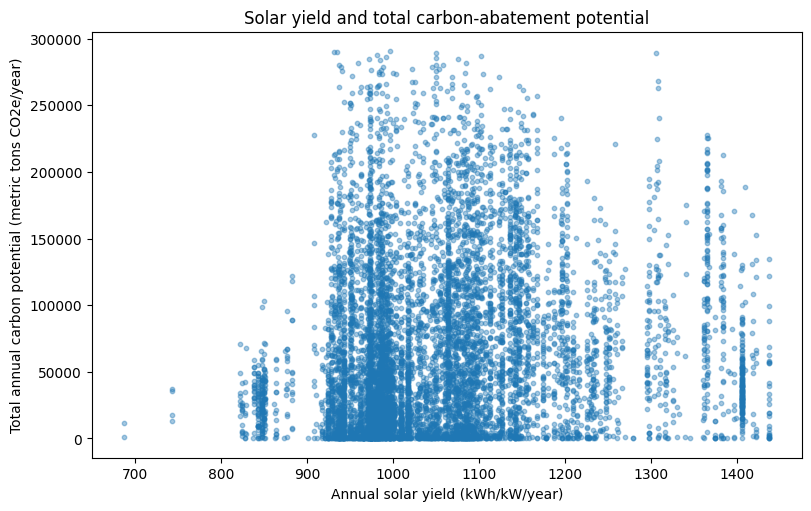

In [6]:
# TODO Create a scatter plot where each row (i.e. Zipcode) is a point with the following axes:
# X axis: The value corresponding to the 'yearly_sunlight_kwh_kw_threshold_avg' key -- this is the amount of energy (kWh) produced in an average year by a 1 kW solar panel in that Zipcode
# Y axis: The value corresponding to the 'carbon_offset_metric_tons' key -- this is the amount of CO2 that would not be emitted for every kWh of energy produced via clean energy.
# Axes should be labelled appropriately and a title should be given.

x = df[SUN]
y = df[CARBON]

solar_labels = {
    "xlabel": "Annual solar yield (kWh/kW/year)",
    "ylabel": "Total annual carbon potential (metric tons CO2e/year)",
    "title": "Solar yield and total carbon-abatement potential"
}

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
ax.scatter(x, y, s=10, alpha=0.4, color="tab:blue")
ax.set(**solar_labels)
plt.show()

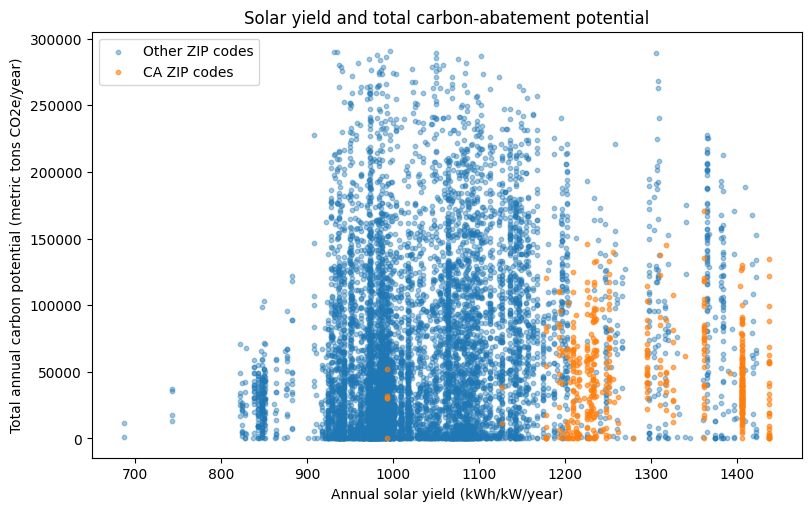

In [7]:
# TODO Modify your plot such that the ZipCodes from California are all in a different color.

def in_state(frame, name):
    return frame["state_name"].eq(name).to_numpy()

is_ca = in_state(df, "California")

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
ax.scatter(x[~is_ca], y[~is_ca], s=10, alpha=0.4, color="tab:blue", label="Other ZIP codes")
ax.scatter(x[is_ca], y[is_ca], s=10, alpha=0.6, color="tab:orange", label="CA ZIP codes")
ax.set(**solar_labels)
ax.legend()
plt.show()

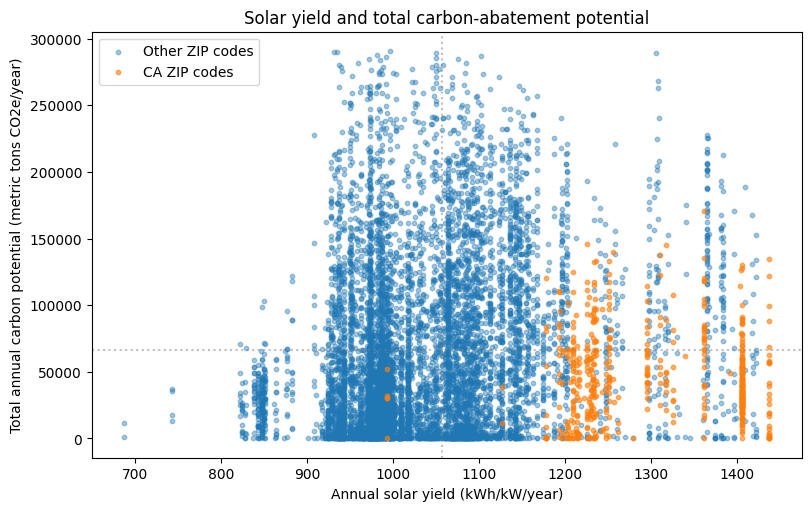

In [8]:
# TODO Further modify your plot such that there is a vertical dotted line (gray with alpha = 0.5) showing the average yearly sunlight value
# And a similar horizontal line for the y axis average.

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
ax.scatter(x[~is_ca], y[~is_ca], s=10, alpha=0.4, color="tab:blue", label="Other ZIP codes")
ax.scatter(x[is_ca], y[is_ca], s=10, alpha=0.6, color="tab:orange", label="CA ZIP codes")
ax.axvline(x.mean(), color="gray", linestyle=":", alpha=0.5)
ax.axhline(y.mean(), color="gray", linestyle=":", alpha=0.5)
ax.set(**solar_labels)
ax.legend()
plt.show()

## 4 -- Generalized Scatter plot (10)
Now we will write a function that can generalize this to arbitrary keys and subsets of the dataset.

In [9]:
# Complete the following plotting function, instructions are given via the comment

def paired_values(x, y):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    return x, y, np.isfinite(x) & np.isfinite(y)

def scatter_plot(x_values, y_values, stats_line=None, masks=()):
    x, y, valid = paired_values(x_values, y_values)
    fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")

    covered = np.zeros(len(x), dtype=bool)
    for mask, name, color in masks:
        covered |= np.asarray(mask, dtype=bool)

    other = valid & ~covered
    ax.scatter(x[other], y[other], s=10, alpha=0.4, color="tab:blue", label="Other ZIP codes" if masks else None)

    for mask, name, color in masks:
        selected = valid & np.asarray(mask, dtype=bool)
        ax.scatter(x[selected], y[selected], s=10, alpha=0.6, color=color, label=name)

    if stats_line is not None and valid.any():
        statistic = {"mean": np.mean, "median": np.median}[stats_line]
        ax.axvline(statistic(x[valid]), color="gray", linestyle=":", alpha=0.5)
        ax.axhline(statistic(y[valid]), color="gray", linestyle=":", alpha=0.5)

    if masks:
        ax.legend()

    return ax

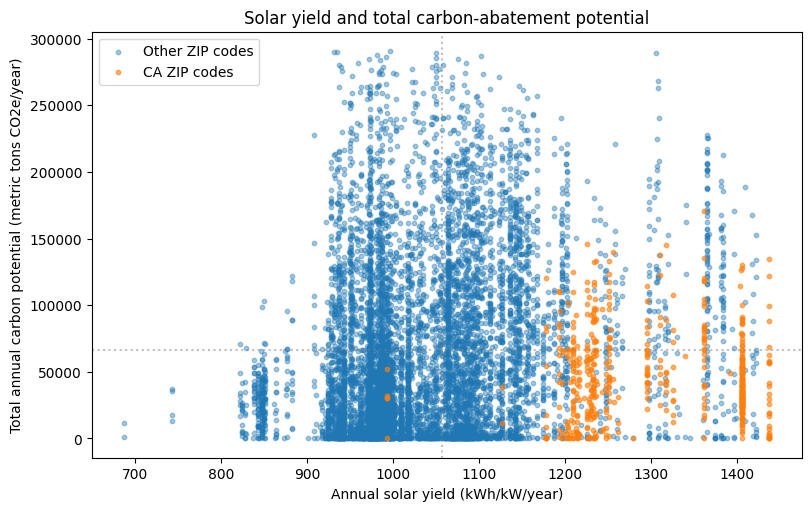

In [10]:
# TODO Show that your function works by reproducing your plot from above using a call to this function

ca = [(in_state(df, "California"), "CA ZIP codes", "tab:orange")]
ax = scatter_plot(df[SUN], df[CARBON], stats_line="mean", masks=ca)
ax.set(**solar_labels)
plt.show()

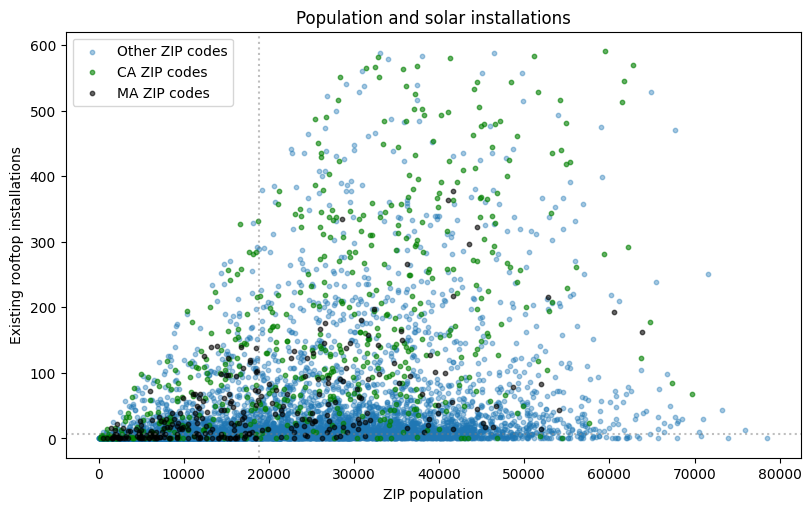

In [11]:
# TODO show that it works with other values by producing a new graph plotting 'Total_Population' versus 'existing_installs_count'
# With lines showing the median drawn
# And with CA zipcodes drawn in green and MA zipcodes drawn in black.

states = [
    (in_state(df, "California"), "CA ZIP codes", "green"),
    (in_state(df, "Massachusetts"), "MA ZIP codes", "black")
]

population_labels = {
    "xlabel": "ZIP population",
    "ylabel": "Existing rooftop installations",
    "title": "Population and solar installations"
}

ax = scatter_plot(df[POP], df[INSTALLS], stats_line="median", masks=states)
ax.set(**population_labels)
plt.show()

## 5 -- Complex Scatters/polynomial fits (30)
Now we will modify our code to include polynomial fits to our masked subsets. Doing only a linear fit will give 50% credit on this part.

In [12]:
# TODO modify your above code such that a new element is added to your 'masks' tuples as explained below

def complex_scatter_plot(x_values, y_values, stats_line=None, masks=()):
    ax = scatter_plot(x_values, y_values, stats_line, [mask[:3] for mask in masks])
    x, y, valid = paired_values(x_values, y_values)

    for mask, name, color, degree in masks:
        selected = valid & np.asarray(mask, dtype=bool)
        xm, ym = x[selected], y[selected]

        if np.unique(xm).size <= degree:
            print(f"Skipping {name}: insufficient distinct x values for degree {degree}.")
            continue

        polynomial = np.polynomial.Polynomial.fit(xm, ym, degree)
        grid = np.linspace(xm.min(), xm.max(), 200)
        ax.plot(grid, polynomial(grid), color=color, alpha=0.5, label=f"{name}: degree {degree}")

    if masks:
        ax.legend()

    return ax

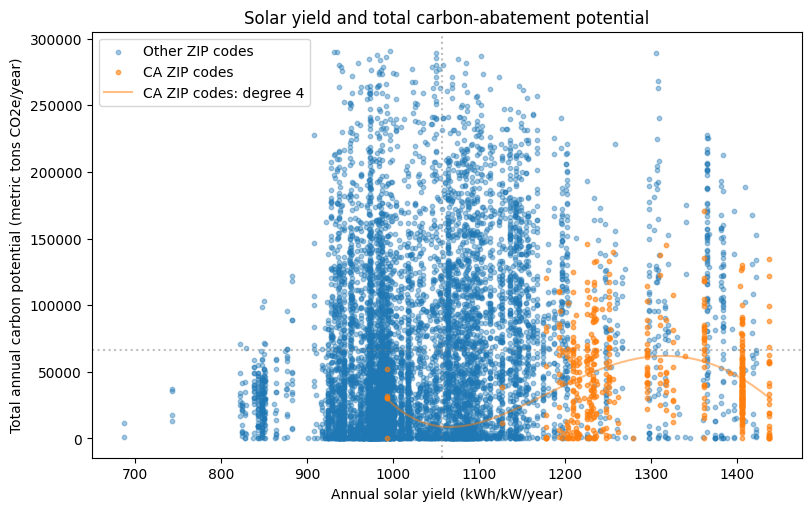

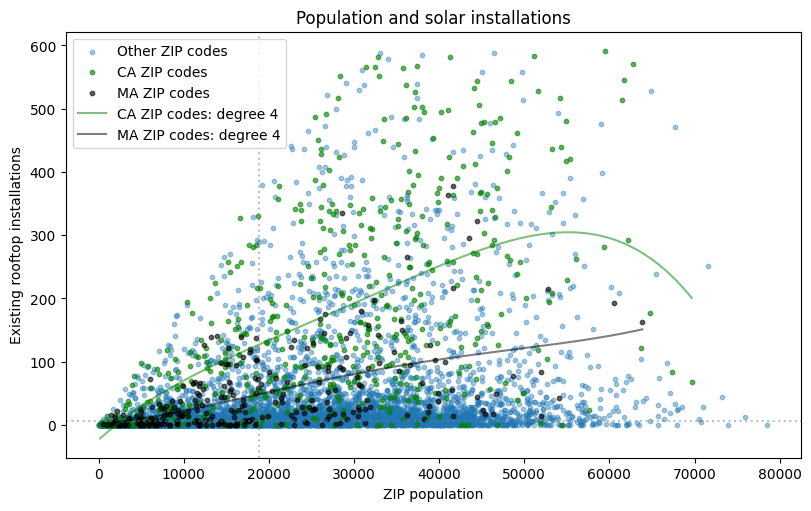

In [13]:
# TODO show that your code works by showing the plots from part 4 with each mask having a 4 degree polynomial fit. Show only linear fits if that is the only fit completed.

# Fourth degree fit for the solar scatter
ca_fits = [(mask, name, color, 4) for mask, name, color in ca]
ax = complex_scatter_plot(df[SUN], df[CARBON], stats_line="mean", masks=ca_fits)
ax.set(**solar_labels)
plt.show()

# Fourth degree fits for populations vs installations
state_fits = [(mask, name, color, 4) for mask, name, color in states]
ax = complex_scatter_plot(df[POP], df[INSTALLS], stats_line="median", masks=state_fits)
ax.set(**population_labels)
plt.show()

## 6 -- Pearson Correlation (10)
We will now implement a pearson correlation calculation for any two sets of values. The Pearson correlation coefficient intuitively represents how closesly two sets, X and Y, are to a purely linear relationship (i.e. Y = w * X + b, for some w and b) with value 1 meaning a perfect linear fit and 0 meaning completely uncorrelated data.
<\br><\br>
Specifically Pearson Correlation Coefficient (PCC) is calculated like so:
\begin{align*}
PCC(X,Y) = \frac{cov(X,Y)}{\sigma_X \sigma_Y}
\end{align*}
Where, 
\begin{align*}
cov(X,Y) = \mathbb{E}[(X - \mu_X)(Y - \mu_Y)]
\end{align*}
With: $\mu_X$ is the average of X and $\sigma_X$ is the standard deviation of X.


In [14]:
# TODO complete the implementation of Pearson Correlation

def pearson_corr(X, Y):
    x, y, valid = paired_values(X, Y)
    x, y = x[valid], y[valid]
    if len(x) < 2:
        return np.nan
    x, y = x - x.mean(), y - y.mean()
    denominator = np.sqrt(np.dot(x, x)) * np.sqrt(np.dot(y, y))
    if denominator == 0:
        return np.nan
    return float(np.clip(np.dot(x, y) / denominator, -1, 1))

In [15]:
# TODO report the pearson correlation of the following pairs:

'''
total population vs existing installs:
    - In all ZIP codes
    - In CA ZIP codes
    - In MA ZIP codes

Median Income (find the exact key in the csv) vs installs per capita (existing installs / population of each ZIP)
    - In all ZIP codes
    - In CA ZIP codes
    - In MA ZIP codes    

'''
def correlation_report(frame):
    rows = []
    scopes = {
        "All available ZIPs": frame,
        "CA": frame.loc[in_state(frame, "California")],
        "MA": frame.loc[in_state(frame, "Massachusetts")]
    }
    for name, subset in scopes.items():
        population = subset[POP]
        per_capita = subset[INSTALLS] / population.where(population > 0)
        rows.append({
            "Scope": name,
            "Population vs installations": pearson_corr(population, subset[INSTALLS]),
            "Income vs installations per capita": pearson_corr(subset[INCOME], per_capita)
        })
    return pd.DataFrame(rows).set_index("Scope")

report = correlation_report(df)
print(report.round(4).to_string())

                    Population vs installations  Income vs installations per capita
Scope                                                                              
All available ZIPs                       0.3453                              0.1819
CA                                       0.5419                              0.4227
MA                                       0.5251                              0.2571


## 7 -- Pearson correlation heatmap (15)
Now we will use our pearson correlation calculations to produce heatmaps for data analysis

In [16]:
# TODO complete the heatmap function below

KEYS = [INCOME, INSTALLS, "black_prop", "asian_prop", SUN, CARBON, POP]
LABELS = ["Median income", "Installations", "Black proportion", "Asian proportion", "Solar yield", "Total carbon potential", "Population"]

def pearson_matrix(dataframe, keys):
    matrix = np.full((len(keys), len(keys)), np.nan)
    for i, first in enumerate(keys):
        for j in range(i, len(keys)):
            matrix[i, j] = matrix[j, i] = pearson_corr(dataframe[first], dataframe[keys[j]])
    return pd.DataFrame(matrix, index=keys, columns=keys)

def draw_heatmap(matrix, title, limit=1):
    fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
    labels = LABELS if list(matrix.columns) == KEYS else list(matrix.columns)
    sn.heatmap(matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-limit, vmax=limit, square=True, ax=ax, xticklabels=labels, yticklabels=labels)
    ax.set_title(title)
    ax.tick_params(axis="y", rotation=0)
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
    return ax

def pearson_heatmap(dataframe, keys):
    correlations = pearson_matrix(dataframe, keys)
    shown = correlations.to_numpy(copy=True)
    pairs = shown[np.triu_indices(len(keys), k=1)]
    finite = pairs[np.isfinite(pairs)]
    np.fill_diagonal(shown, finite.mean() if finite.size else np.nan)
    draw_heatmap(pd.DataFrame(shown, index=keys, columns=keys), "Pearson correlations; diagonal = mean of valid unique pairs")
    return correlations

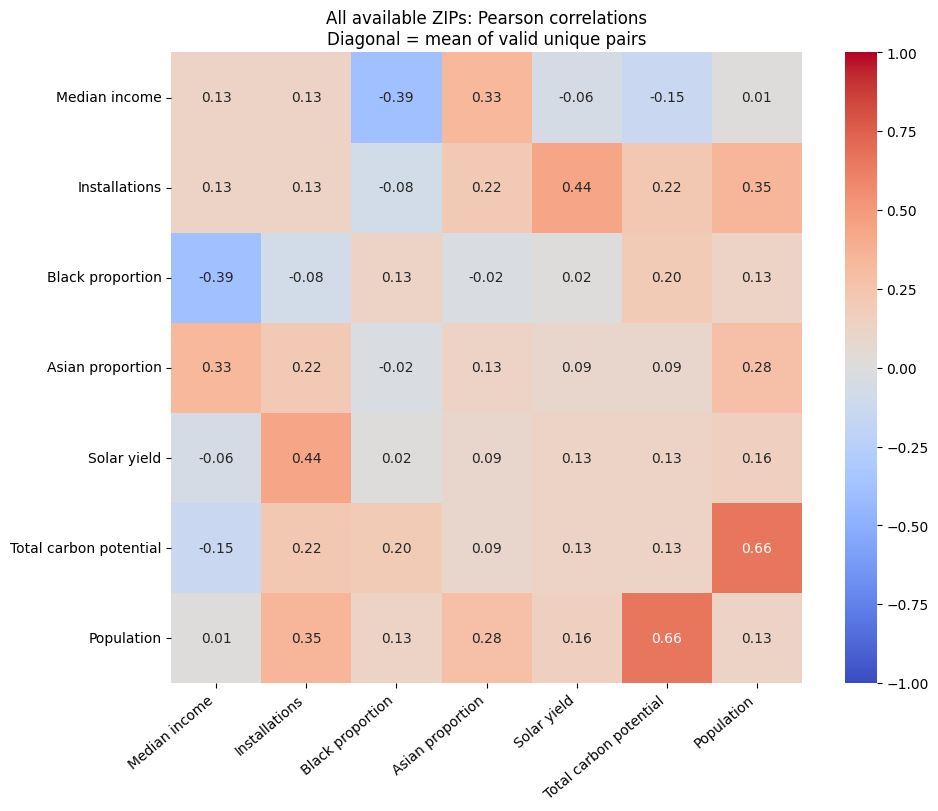

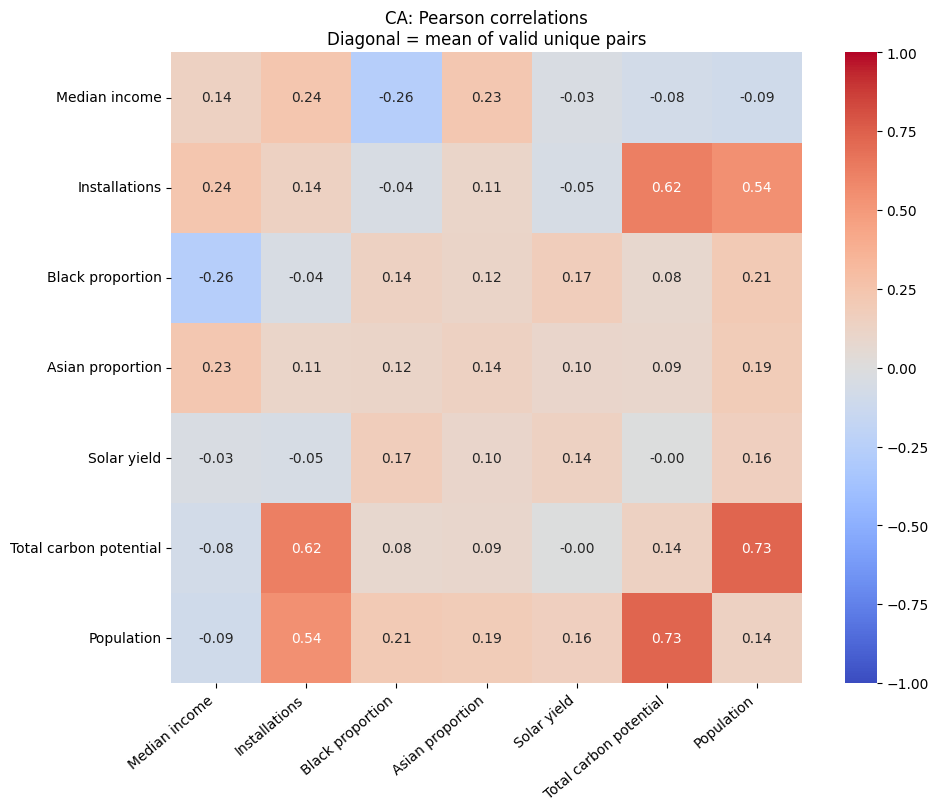

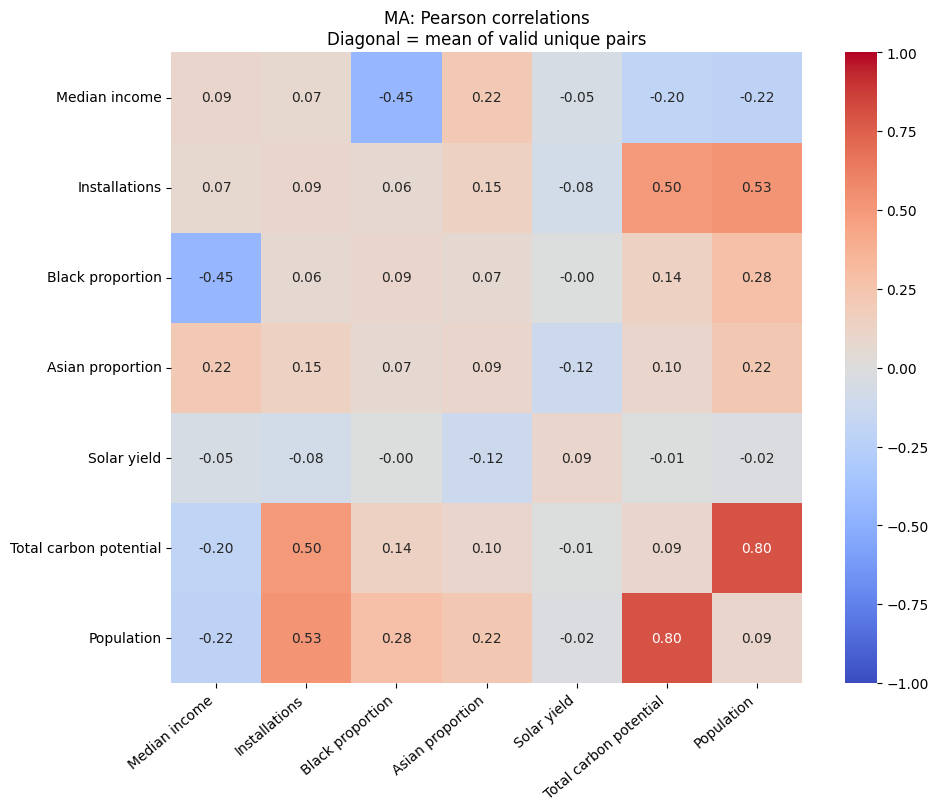

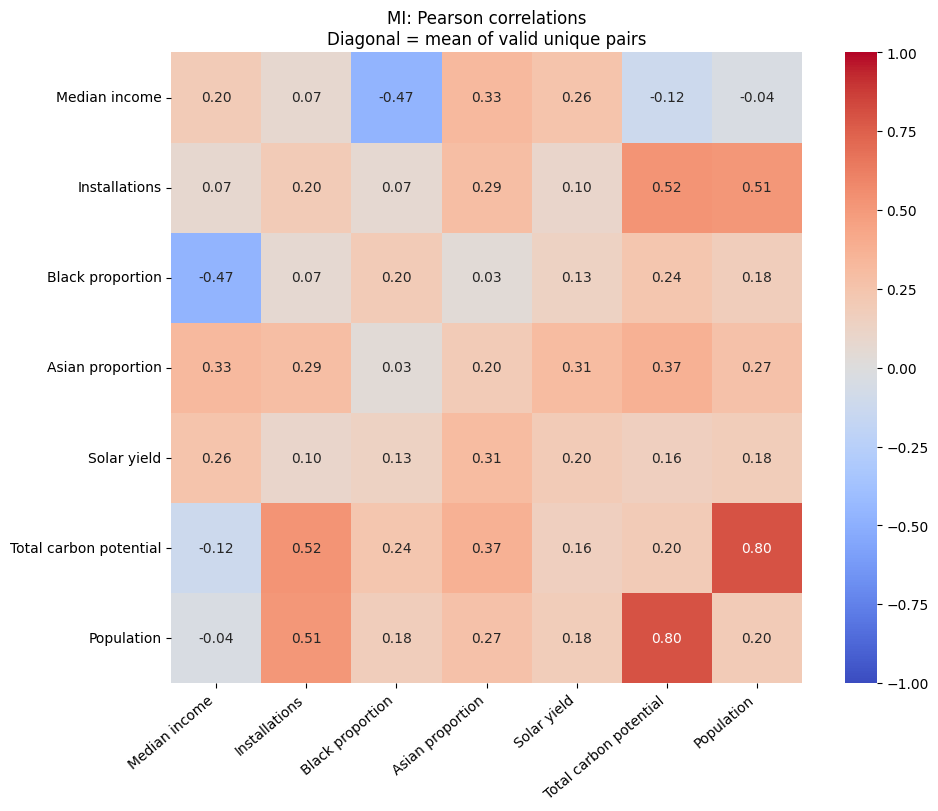

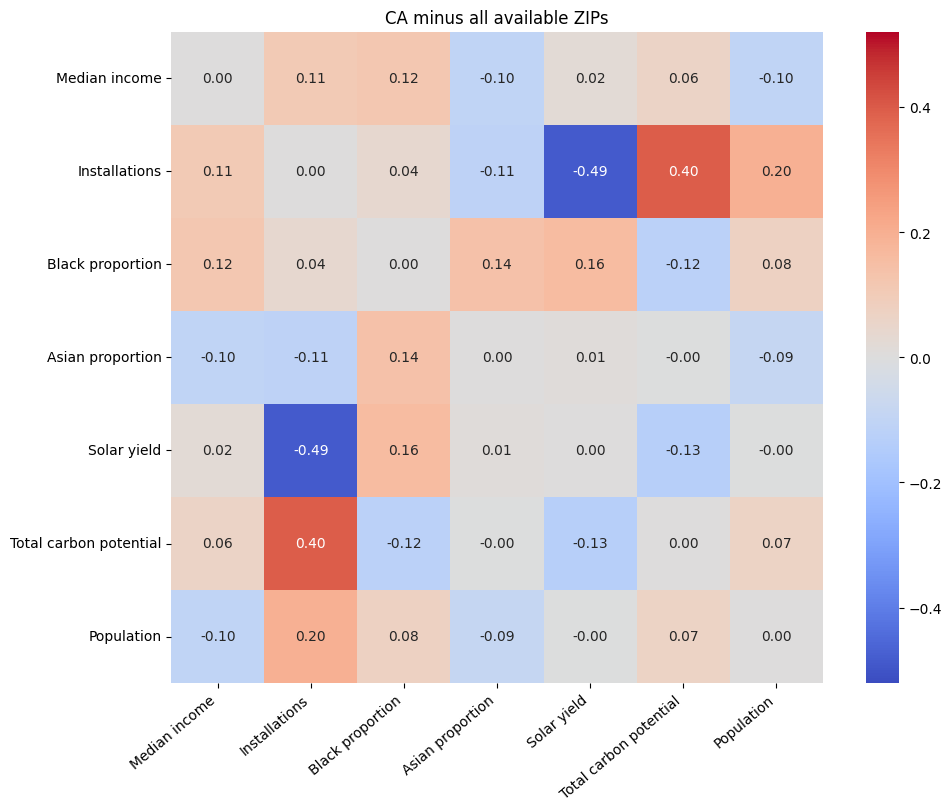

CA: largest absolute difference: existing_installs_count vs yearly_sunlight_kwh_kw_threshold_avg; state r=-0.0497, all-ZIP r=+0.4381, difference=-0.4878


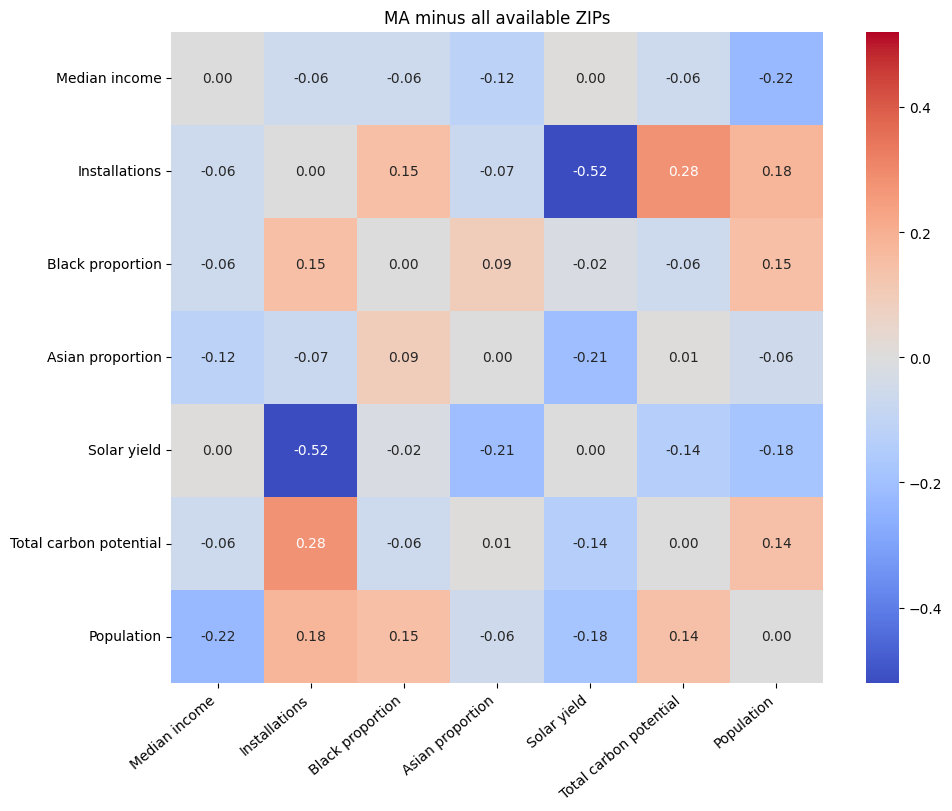

MA: largest absolute difference: existing_installs_count vs yearly_sunlight_kwh_kw_threshold_avg; state r=-0.0828, all-ZIP r=+0.4381, difference=-0.5210


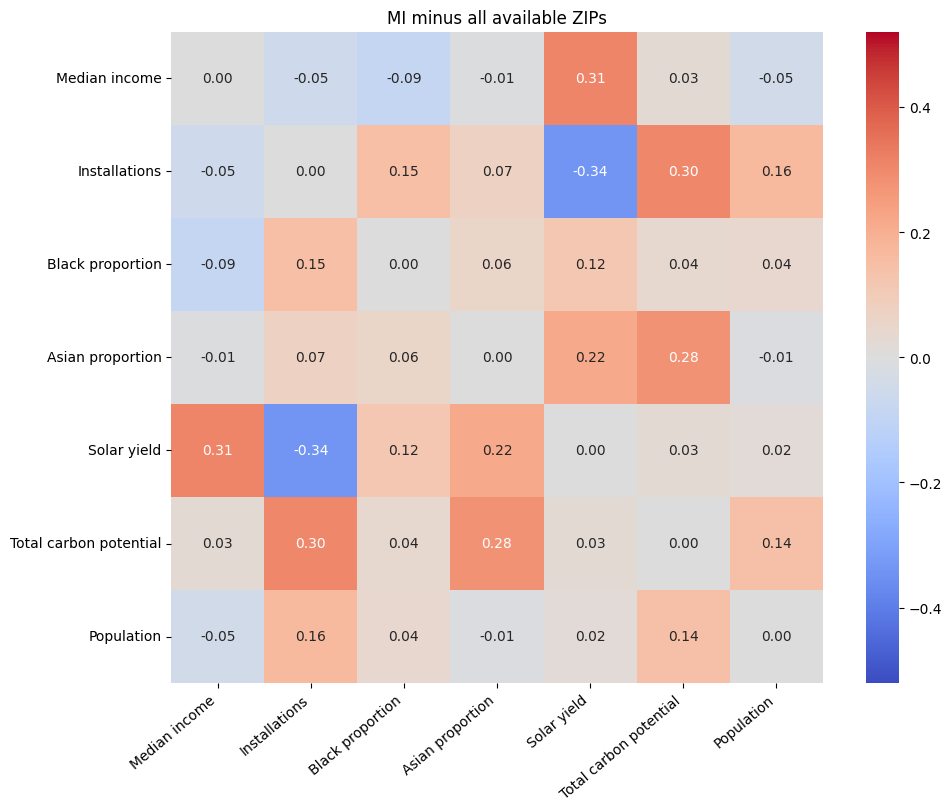

MI: largest absolute difference: existing_installs_count vs yearly_sunlight_kwh_kw_threshold_avg; state r=+0.0992, all-ZIP r=+0.4381, difference=-0.3390


In [17]:
# TODO use this to show the pearson correlations of the following keys

# For: all the zips, just CA zips, just MA zips, and just MI zips -- that is 4 heatmaps

def compare_state_heatmaps(frame):
    scopes = {"All available ZIPs": frame}
    for code, name in [("CA", "California"), ("MA", "Massachusetts"), ("MI", "Michigan")]:
        scopes[code] = frame.loc[in_state(frame, name)]
    correlations = {}

    for name, subset in scopes.items():
        correlations[name] = pearson_heatmap(subset, KEYS)
        plt.gca().set_title(f"{name}: Pearson correlations\nDiagonal = mean of valid unique pairs")
        plt.show()

    differences = {}
    for state in ("CA", "MA", "MI"):
        difference = correlations[state] - correlations["All available ZIPs"]
        np.fill_diagonal(difference.values, 0)
        differences[state] = difference
    limit = max(0.01, max(np.nanmax(np.abs(d.values)) for d in differences.values()))
    upper = np.triu_indices(len(KEYS), k=1)

    for state, difference in differences.items():
        draw_heatmap(difference, f"{state} minus all available ZIPs", limit)
        plt.show()
        values = difference.to_numpy()[upper]
        finite = np.flatnonzero(np.isfinite(values))
        if not finite.size:
            print(f"{state}: no defined off-diagonal differences.")
            continue

        k = finite[np.argmax(np.abs(values[finite]))]
        i, j = upper[0][k], upper[1][k]
        print(f"{state}: largest absolute difference: {KEYS[i]} vs {KEYS[j]}; state r={correlations[state].iloc[i, j]:+.4f}, all-ZIP r={correlations['All available ZIPs'].iloc[i, j]:+.4f}, difference={values[k]:+.4f}")
    return correlations, differences

correlations, differences = compare_state_heatmaps(df)

In [18]:
# TODO: Additionally, for each state-specific heatmap show the different of the heatmap to the all ZIP heatmap (that is, a new heatmap with the diagnoal entries = 0) 
# And report the correlation entry which is most different for each of these states compared to the full dataset.

## 8 -- Concluding Analysis (10)
Now, using all of the results that you've visualized, make some conclusions -- you are graded here based on the correctness of your conclusion and how compelling the argument you make is.

#### 8a. If the intention of installing solar panels is to both increase energy generation and carbon offset how good is the current distribution of panels?

The current distribution shows some alignment with energy generation, but these results do not establish that it jointly optimizes generation and carbon offset. Across the cleaned sample, solar yield and installation count have a positive correlation of 0.4381. However, this association is much weaker within California, Massachusetts, and Michigan. The national relationship therefore reflects geographic differences between states as well as relationships within them; it should not be interpreted as evidence that installations consistently favor the best solar resources locally.

Income also has a positive association with installations per capita: 0.1819 across the sample, 0.4227 in California, and 0.2571 in Massachusetts. This indicates that adoption varies with ZIP-level income, even after dividing installation counts by population. It does not establish that income causes adoption, nor does it isolate other influences such as homeownership, roof suitability, electricity prices, or policy.

The carbon scatter requires particular care. carbon_offset_metric_tons measures total technical abatement potential across suitable roof space. A ZIP may have a high value because it contains substantial roof capacity, because its solar output displaces carbon-intensive electricity, or both. Consequently, the requested plots cannot directly measure the existing fleet’s carbon efficiency. The first paper provides separate simulation evidence that carbon-aware siting can improve carbon reductions compared with existing deployment trends.

A defensible conclusion is that deployment has some association with solar resource and income, while its joint energy–carbon efficiency remains unproven by these plots alone. These findings also apply specifically to the covered ZIP codes surviving the prescribed cleaning procedure, rather than to every US ZIP code.

#### 8b. If you were to add n new solar panels in zip codes of your choosing how would you decide where to put them if attempting to co-maximize energy generation and carbon offset?

I would compare ZIP codes using their estimated per-panel energy generation and carbon offset, then make the trade-off between those objectives explicit.

For ZIP $i$, let $P_i$ be number_of_panels_total, $T_i$ be yearly_sunlight_kwh_total, and $B_i$ be carbon_offset_metric_tons. For $P_i>0$, the uniform-average-panel approximation gives

$$
E_i=\frac{T_i}{P_i},
\qquad
C_i=\frac{B_i}{P_i}.
$$

Here, $E_i$ is annual energy generation in kWh per panel, and $C_i$ is annual carbon offset in metric tons per panel. Carbon offset already incorporates energy generation, so multiplying $B_i$ by sunlight again would double-count that contribution.

Choose positive reference scales $E_{\mathrm{ref}}$ and $C_{\mathrm{ref}}$, such as the maximum eligible per-panel values, and an explicit policy weight $0<\alpha<1$. Then assign each ZIP the score

$$
s_i=\alpha\frac{E_i}{E_{\mathrm{ref}}}+(1-\alpha)\frac{C_i}{C_{\mathrm{ref}}}.
$$

If $a_i$ panels are allocated to ZIP $i$, and its verified remaining capacity is $u_i$, the allocation problem is

$$
\max \sum_i a_i s_i,
\qquad
\sum_i a_i=n,
\qquad
0\leq a_i\leq u_i,
\qquad
a_i\in\mathbb{Z}.
$$

Under equal panel costs, fixed marginal benefits, and only these constraints, sorting ZIPs by score and filling them in descending order is optimal. To see why, suppose an allocation places a panel in a lower-scoring ZIP while a higher-scoring ZIP still has capacity. Moving that panel to the higher-scoring ZIP cannot reduce the objective. Repeating this exchange produces the greedy allocation.

The capacity values need independent attention. existing_installs_count counts rooftop installations or buildings, whereas number_of_panels_total counts individual panels. Subtracting the former from the latter does not produce a valid estimate of remaining panel capacity. Without existing panel inventories, total technical roof capacity is only an optimistic upper bound.

Varying $\alpha$ exposes different energy–carbon compromises, although weighted sums can miss unsupported Pareto-optimal allocations in a discrete problem. The resulting allocation is optimal for the stated simplified model; its real-world performance still depends on the accuracy of capacity estimates, average yields, grid emission factors, and the equal-cost assumption.

---

## ------------------------ END OF MOCK AIO QUESTION -------------------------------------------------

---

## Extension (Research)

Below are some extention questions for interested students. In particular, this is the begininng of my recent research work (1st paper is: https://dl.acm.org/doi/10.1145/3679240.3734603, 2nd is here: https://dl.acm.org/doi/pdf/10.1145/3736425.3770115, 3rd is being published soon but I can share it if you are interested). If any of you are interested and able to work on this effectively then I would consider a research mentorship to help on the 4th/5th paper in the series and perhaps earn authorship.
</br></br>
You may reference the library I created for these works (you can also find implementations of the problem you just did in it) here: https://github.com/coopersigrist/SunSight
</br></br>
If you finish all of these problems with high competency I will almost definitely take you on for the next paper and give you an authorship position.

# EX 1. Find 3 other notable and relevant statistics from this data -- You may use any techniques.

### Extension 1 : Three additional statistics

This analysis examines three complementary questions:

1. Does income remain associated with solar adoption after accounting for state differences and observable installation opportunities?
2. Are ZIP codes with high carbon-offset potential represented in existing installations in proportion to their suitable-building availability?
3. How much greater carbon-offset potential is available at locations with no lower per-panel energy potential?

These are descriptive analyses of the supplied dataset, not causal estimates or forecasts of achievable deployment improvements.

### Data and sensitivity analysis

The primary analysis uses the cleaned dataset from the preceding sections. To assess sensitivity to the prescribed outlier filtering, the calculations are repeated using the original dataset with valid required fields. A third analysis restricts that original-data sample to ZIP codes with Project Sunroof coverage of at least 75%.

For research-specific preparation, observations must have finite values in the required fields. Income, population, suitable-building count, coverage, solar resource, panel potential, energy potential, and carbon potential must be positive. Existing installation counts must be nonnegative, and coverage cannot exceed 100%.

The high-carbon quartile and the set of eligible comparison locations are recalculated within each sample. Consequently, the sensitivity analysis applies the same definitions to different samples rather than holding group membership fixed.

| Measure | Cleaned sample | Original data with valid required fields | Original data with coverage ≥75% |
|:--|--:|--:|--:|
| Number of ZIP codes | 8,392 | 10,543 | 7,787 |
| Adjusted income–adoption correlation | 0.2180 | 0.2604 | 0.2719 |
| High-carbon group's installation share | 5.77% | 6.90% | 6.76% |
| High-carbon group's suitable-building share | 23.43% | 23.05% | 23.67% |
| High-carbon representation ratio | 0.2461 | 0.2992 | 0.2855 |
| Median energy-preserving carbon opportunity | 45.30% | 46.94% | 46.97% |

### 1. Adjusted income–adoption correlation

The earlier correlation between median income and installations per capita may partly reflect differences in geography, solar resources, population, and roof availability. This analysis measures the association remaining after a specified adjustment for those characteristics.

For ZIP code $i$, define transformed adoption as

$$
A_i = \log\left(1 + 1000\frac{I_i}{N_i}\right),
$$

where $I_i$ is the existing rooftop-installation count and $N_i$ is population. The factor of 1,000 expresses installations per thousand residents. The logarithmic transformation reduces the influence of unusually large adoption rates while retaining observations with zero installations.

Define transformed income as

$$
H_i = \log(M_i),
$$

where $M_i$ is ZIP-level median income.

The control matrix $Z$ contains an intercept, state indicators, log population, log suitable buildings per resident, the solar-resource variable, and coverage percentage. The continuous controls are standardized before fitting.

Both transformed variables are regressed on the same controls:

$$
H = Z\beta_H + \varepsilon_H,
$$

$$
A = Z\beta_A + \varepsilon_A.
$$

The statistic is the correlation between their fitted residuals:

$$
r_{\mathrm{adjusted}}
=
\operatorname{corr}\left(\hat{\varepsilon}_H,\hat{\varepsilon}_A\right).
$$

The residuals represent variation not explained by the specified linear control model. Their correlation therefore measures the remaining linear association between transformed income and adoption.

**Result.** The adjusted correlation is **0.2180** in the cleaned sample. It remains positive in the original valid-field sample (**0.2604**) and the higher-coverage sample (**0.2719**).

For comparison, the unadjusted correlation between the same transformed variables in the cleaned sample is **0.2073**. The association therefore does not disappear after adjustment. These transformed-variable correlations are not directly comparable with the earlier correlation of **0.1819**, which used untransformed income and installations per capita.

**Interpretation.** Higher ZIP-level income remains positively associated with adoption after accounting for the specified observable characteristics and state differences.

This is not a causal effect of income. Homeownership, financing access, roof condition, electricity tariffs, and local policies may still matter. The adjustment is also limited to the functional form of the control model. Finally, an association between ZIP-level measurements does not establish the corresponding relationship between individual households.

### 2. Representation of carbon-efficient ZIP codes

This statistic compares the share of installations in high-carbon-potential ZIP codes with their share of suitable buildings.

Let $B_i$ be `carbon_offset_metric_tons` and $P_i$ be `number_of_panels_total`. Average annual technical carbon-offset potential per panel is

$$
C_i = 1000\frac{B_i}{P_i}.
$$

The factor of 1,000 converts metric tons to kilograms, giving units of kg CO₂e per panel per year.

Define the high-carbon group as

$$
G = \left\{i : C_i \geq Q_{0.75}(C)\right\},
$$

where $Q_{0.75}(C)$ is the sample's 75th percentile.

Let $Q_i$ denote `count_qualified`, the number of suitable buildings. Calculate the group's installation share and suitable-building share:

$$
s_I = \frac{\sum_{i\in G} I_i}{\sum_i I_i},
$$

$$
s_Q = \frac{\sum_{i\in G} Q_i}{\sum_i Q_i}.
$$

The representation ratio is

$$
R = \frac{s_I}{s_Q}.
$$

Equivalently,

$$
R =
\frac{\left(\sum_{i\in G} I_i\right)/\left(\sum_{i\in G} Q_i\right)}
{\left(\sum_i I_i\right)/\left(\sum_i Q_i\right)}.
$$

Thus, $R$ compares installations per suitable building in the high-carbon group with the overall sample rate. A value of 1 indicates proportional representation; a value below 1 indicates underrepresentation relative to this benchmark.

**Result.** In the cleaned sample, the high-carbon threshold is approximately **218.58 kg CO₂e per panel per year**, and the group contains **2,098 ZIP codes**. These ZIP codes contain **23.43% of suitable buildings** but only **5.77% of existing installations**:

$$
R = \frac{0.057662}{0.234272} \approx 0.2461.
$$

Their installations per suitable building are approximately **24.6% of the overall sample rate**, or **75.4% lower**.

**Interpretation.** High-carbon-potential ZIP codes are substantially underrepresented in existing installations relative to their suitable-building availability.

The denominator matters: existing installations count rooftop systems or buildings, so suitable buildings provide a more compatible comparison than individual potential-panel counts.

This benchmark does not establish that every suitable building is available for development or that proportional representation is the uniquely correct allocation. System size, ownership, costs, and practical roof availability may differ between groups. Coverage differences may also affect the recorded counts. The higher-coverage sensitivity analysis supports the direction of the finding but does not fully correct these limitations.

### 3. Median energy-preserving carbon opportunity

This statistic asks whether an observed alternative location offers greater carbon-offset potential without reducing per-panel energy potential.

Let $T_i$ be `yearly_sunlight_kwh_total`. Average annual technical energy potential per panel is

$$
E_i = \frac{T_i}{P_i}.
$$

For each ZIP code, define the greatest carbon potential available among locations with at least as much energy potential:

$$
C_i^\star = \max_{j:E_j\geq E_i} C_j.
$$

The energy-preserving carbon opportunity for ZIP code $i$ is

$$
g_i = 100\left(\frac{C_i^\star}{C_i}-1\right).
$$

Each ZIP can serve as its own comparator, so $g_i\geq0$. The reported statistic is

$$
G_{\mathrm{median}} = \operatorname{median}_i(g_i).
$$

For example, consider a location offering 400 kWh and 150 kg CO₂e per panel annually. If another offers 420 kWh and 225 kg CO₂e, its energy-preserving carbon opportunity is

$$
100\left(\frac{225}{150}-1\right)=50\%.
$$

The alternative has greater carbon potential and no lower energy potential.

**Computation.** ZIP codes are grouped by identical energy values, retaining each group's maximum carbon value. The groups are sorted by descending energy, and a cumulative maximum of carbon is calculated. At each energy level, this cumulative maximum is exactly $C_i^\star$, because it considers all locations with equal or greater energy potential.

Grouping equal-energy observations before the cumulative maximum ensures that all eligible tied observations are considered.

**Result.** The median opportunity is **45.30%** in the cleaned sample. It is **46.94%** in the original valid-field sample and **46.97%** in the higher-coverage sample.

**Interpretation.** The median ZIP has an observed alternative with approximately **45.3% greater average per-panel carbon potential and no lower average per-panel energy potential**.

A positive opportunity identifies a location dominated by another on these two modeled objectives. This connects the statistic to the Pareto reasoning discussed in Paper 2.

However, this is not a prediction of a 45.3% improvement in national carbon reductions. Multiple ZIP codes may share the same best comparator, whose available capacity is finite. The comparison also excludes costs, equity, transmission constraints, and differences between average technical potential and actual marginal deployment outcomes.

### Overall findings and limitations

The three statistics provide complementary evidence:

- Income remains positively associated with adoption after the specified adjustment.
- High-carbon-potential ZIP codes have substantially fewer installations per suitable building than the overall sample.
- Substantial differences in carbon potential exist even when requiring comparison locations to have no lower per-panel energy potential.

The directions persist across the three sample definitions, supporting robustness to these particular filtering and coverage choices.

These are descriptive effect sizes rather than causal estimates. Ordinary significance tests assuming independent ZIP codes would require care because nearby locations may share grids, policies, housing markets, and other characteristics. The dataset also has incomplete geographic coverage, and its technical potential estimates do not establish the feasibility of particular installations.

### References

1. Sigrist et al. (2025). *Lost in Siting: The Hidden Carbon Cost of Inequitable Residential Solar Installations*. See Section 3 for the relationships among adoption, demographics, and carbon potential. https://doi.org/10.1145/3679240.3734603

2. Sigrist et al. (2025). *Multi-objective Evolutionary Learning for Near Pareto-Optimal Optimization of Solar Deployment*. See Sections 3.3 and 4.2 for Pareto reasoning and the energy, carbon, and equity objectives. https://doi.org/10.1145/3736425.3770115

# EX 2. Create an algorithm which places n panels in zip codes with the goal to maximize energy generation and carbon offset. Give pseudo-code for your algorithm and show a map of the locations that 2 million panels would be placed (I recommend using the visualization in the SunSight library) 

### Extension 2 : Capacity-constrained energy-carbon allocation

### Objective

The goal is to allocate exactly $n$ additional individual panels while jointly considering annual energy generation and carbon offset.

The two objectives need not attain their separate maxima at the same locations. Therefore, "co-maximization" requires an explicit rule for choosing a compromise.

I use a max–min criterion: maximize the smaller fraction of the energy-only and carbon-only optima that the allocation retains.

This is a standard multi-objective decision principle, implemented here through independently written weighted-greedy searches and an optimality bound. It is not presented as a new optimization theory or as a reproduction of EVA.

### Data and physical units

The analysis uses the original CSV, retaining ZIP codes with valid required fields and coordinates within the contiguous-US study region. Unlike the earlier all-column outlier filter, this preparation does not exclude locations merely because an unrelated demographic variable is extreme.

For ZIP code $i$, let:

- $P_i$: `number_of_panels_total`.
- $T_i$: `yearly_sunlight_kwh_total`.
- $B_i$: `carbon_offset_metric_tons`.
- $Q_i$: `count_qualified`.
- $I_i$: `existing_installs_count`.

Average annual technical benefits per panel are

$$
e_i = \frac{T_i}{P_i},
\qquad
c_i = \frac{B_i}{P_i}.
$$

The units are kWh per panel per year for $e_i$ and metric tons CO₂e per panel per year for $c_i$.

These quantities use the individual-panel unit represented by the CSV. No additional assumption that every panel is a 1 kW system is introduced, and total carbon potential is not multiplied by sunlight again.

The model assumes each additional panel within a ZIP receives the same average benefit. Actual marginal roof opportunities may differ.

### Remaining-capacity scenario

Existing installations count rooftop systems or buildings, whereas $P_i$ counts individual panels. Therefore,

$$
P_i-I_i
$$

is not a valid calculation of remaining panel capacity.

Instead, I use the explicit scenario

$$
u_i =
\left\lfloor
\gamma P_i\left(1-\frac{I_i}{Q_i}\right)
\right\rfloor,
\qquad 0<\gamma\leq1.
$$

The main calculation uses $\gamma=1$.

This scenario assumes that the installation count and suitable-building count refer to comparable coverage, that existing systems occupy suitable buildings, and that the equipped fraction of buildings represents the same fraction of total panel capacity. It also treats that equipped share as unavailable for new panels.

These assumptions are not verified by the dataset. Equipped buildings could have systematically different roof sizes or unused roof space. The formula can therefore overestimate or underestimate remaining capacity; it is not a measured inventory or a guaranteed conservative bound.

The parameter $\gamma$ allows sensitivity analysis by making only a fraction of this modeled capacity available. A deployment study should replace $u_i$ with verified remaining capacity when available.

### Feasible allocations

Let $a_i$ be the number of new panels assigned to ZIP code $i$.

The allocation must satisfy

$$
\sum_i a_i=n,
\qquad
0\leq a_i\leq u_i,
\qquad
a_i\in\mathbb{Z}.
$$

The budget is feasible only if

$$
n\leq\sum_i u_i.
$$

The resulting annual objectives are

$$
E(a)=\sum_i a_i e_i,
\qquad
C(a)=\sum_i a_i c_i.
$$

### Define the balance criterion

First calculate the separate single-objective optima over the same feasible set:

$$
E^\star=\max_a E(a),
\qquad
C^\star=\max_a C(a).
$$

Normalize each allocation by those benchmarks:

$$
r_E(a)=\frac{E(a)}{E^\star},
\qquad
r_C(a)=\frac{C(a)}{C^\star}.
$$

The balanced objective is

$$
L(a)=\min\left(r_E(a),r_C(a)\right).
$$

An allocation scoring $L(a)=0.91$ retains at least 91% of each separate optimum.

This treats proportional shortfalls from the two optima equally. It is an explicit policy choice, rather than a universally correct definition of balance.

### Search method

For each weight $\alpha$ in a grid covering $[0,1]$, calculate the per-panel score

$$
s_i(\alpha)=
\alpha\frac{e_i}{E^\star}
+
(1-\alpha)\frac{c_i}{C^\star}.
$$

Sort ZIP codes by descending score and fill their modeled capacities until exactly $n$ panels have been allocated.

Evaluate each candidate using $L(a)$, and retain the candidate with the largest balanced score. The main calculation uses 1,001 weights.

The selected $\alpha$ is a search parameter identifying a useful supporting allocation. The final decision criterion remains $L(a)$; $\alpha$ is not interpreted as an independently chosen social preference.

### Why each weighted allocation is optimal

For a fixed weight, the objective is linear in panel counts. Every panel consumes one identical unit of the budget.

If an allocation assigns a panel to a lower-scoring ZIP while a higher-scoring ZIP has unused capacity, exchanging those panels cannot reduce the objective. Repeating this exchange yields the greedy allocation.

Therefore, each weighted-greedy solution exactly maximizes its weighted objective under the modeled integer capacity and panel-budget constraints, apart from floating-point numerical precision.

This argument would not automatically apply with unequal panel costs, roof-level installation batches, changing marginal yields, or additional coupled constraints.

### A bound on the global balanced optimum

For any feasible allocation and any $\alpha\in[0,1]$,

$$
L(a)
\leq
\alpha r_E(a)+(1-\alpha)r_C(a).
$$

Let $a_\alpha$ be the weighted-greedy optimizer. Then

$$
L(a)
\leq
\alpha r_E(a_\alpha)+(1-\alpha)r_C(a_\alpha).
$$

Consequently, an upper bound on the globally optimal balanced score is

$$
U=
\min_{\alpha\text{ tested}}
\left[
\alpha r_E(a_\alpha)+(1-\alpha)r_C(a_\alpha)
\right].
$$

If the selected feasible candidate has score $L_{\mathrm{best}}$, then

$$
L_{\mathrm{best}}
\leq
L^\star
\leq
U.
$$

Thus,

$$
U-L_{\mathrm{best}}
$$

bounds its possible suboptimality.

Searching more weights can improve the candidate or tighten the bound, but it does not guarantee that weighted-sum candidates recover every integer max–min optimum. The bound makes this limitation measurable.

### Pseudocode

```text
INPUT: ZIP-level data, panel budget n, capacity scenario gamma, weight grid

Prepare eligible ZIP codes.
Calculate per-panel energy e[i] and carbon c[i].
Calculate modeled remaining capacities u[i].
Reject the budget if n exceeds total modeled capacity.

Define GREEDY(scores):
    Sort ZIP codes by descending score.
    Assign panels in that order, respecting each capacity.
    Stop after assigning exactly n panels.
    Return the integer allocation.

Find the energy-only and carbon-only allocations.
Calculate E_star and C_star from those allocations.

best_score = negative infinity
upper_bound = positive infinity

For each alpha in the weight grid:
    scores[i] = alpha * e[i] / E_star + (1 - alpha) * c[i] / C_star
    allocation = GREEDY(scores)

    energy_fraction = E(allocation) / E_star
    carbon_fraction = C(allocation) / C_star
    balanced_score = min(energy_fraction, carbon_fraction)

    Update the best feasible allocation using balanced_score.
    Update upper_bound using:
        alpha * energy_fraction + (1 - alpha) * carbon_fraction

Return the best allocation, objective totals, and optimality-gap bound.
```

For $Z$ ZIP codes and $K$ tested weights, the search requires approximately

$$
O(KZ\log Z)
$$

time. It allocates in ZIP-level batches rather than looping over two million individual panels.

In [19]:
def prepare_sites(frame, capacity_scale=1.0):
    keys = [
        "region_name", "state_name", "Latitude", "Longitude",
        "number_of_panels_total", "yearly_sunlight_kwh_total",
        "carbon_offset_metric_tons", "count_qualified", "existing_installs_count"
    ]

    sites = frame[keys].replace([np.inf, -np.inf], np.nan).dropna().copy()
    positive = ["number_of_panels_total", "yearly_sunlight_kwh_total", "carbon_offset_metric_tons", "count_qualified"]
    valid = sites[positive].gt(0).all(axis=1) & sites["existing_installs_count"].ge(0) & sites["existing_installs_count"].le(sites["count_qualified"])
    valid &= sites["Latitude"].between(24, 50) & sites["Longitude"].between(-125, -66)
    sites = sites.loc[valid].sort_values("region_name").reset_index(drop=True)

    if sites["region_name"].duplicated().any():
        raise ValueError("ZIP codes must be unique.")

    if not 0 < capacity_scale <= 1:
        raise ValueError("capacity_scale must be in (0, 1].")

    sites["zip"] = sites["region_name"].astype(int).astype(str).str.zfill(5)
    sites["energy"] = sites["yearly_sunlight_kwh_total"] / sites["number_of_panels_total"]
    sites["carbon"] = sites["carbon_offset_metric_tons"] / sites["number_of_panels_total"]

    unused_fraction = 1 - sites["existing_installs_count"] / sites["count_qualified"]
    sites["capacity"] = np.floor(capacity_scale * sites["number_of_panels_total"] * unused_fraction).astype(np.int64)

    return sites.loc[sites["capacity"].gt(0)].reset_index(drop=True)

In [20]:
def greedy_allocation(scores, capacities, n):
    if not isinstance(n, (int, np.integer)) or n <= 0:
        raise ValueError("n must be a positive integer.")

    if n > capacities.sum():
        raise ValueError("Panel budget exceeds modeled capacity.")

    order = np.argsort(-np.asarray(scores), kind="stable")
    sorted_capacity = capacities[order]
    available_budget = n - np.concatenate(([0], np.cumsum(sorted_capacity[:-1])))

    allocation = np.zeros(len(scores), dtype=np.int64)
    allocation[order] = np.minimum(sorted_capacity, np.maximum(available_budget, 0))

    return allocation

In [21]:
def balanced_allocation(sites, n=2_000_000, weights=1001):
    energy = sites["energy"].to_numpy()
    carbon = sites["carbon"].to_numpy()
    capacities = sites["capacity"].to_numpy(dtype=np.int64)

    energy_only = greedy_allocation(energy, capacities, n)
    carbon_only = greedy_allocation(carbon, capacities, n)
    energy_max = energy @ energy_only
    carbon_max = carbon @ carbon_only

    def fractions(allocation):
        return energy @ allocation / energy_max, carbon @ allocation / carbon_max

    best_value = -np.inf
    upper_bound = np.inf

    for alpha in np.linspace(0, 1, weights):
        allocation = greedy_allocation(alpha * energy / energy_max + (1 - alpha) * carbon / carbon_max, capacities, n)
        energy_fraction, carbon_fraction = fractions(allocation)
        upper_bound = min(upper_bound, alpha * energy_fraction + (1 - alpha) * carbon_fraction)

        if min(energy_fraction, carbon_fraction) > best_value:
            best_value = min(energy_fraction, carbon_fraction)
            best_alpha = alpha
            best = allocation

    result = sites.copy()
    result["panels"] = best

    certificate = {
        "alpha": best_alpha,
        "achieved_fraction": best_value,
        "upper_bound": upper_bound,
        "absolute_gap": max(0.0, upper_bound - best_value)
    }

    allocations = {
        "Energy only": energy_only,
        "Carbon only": carbon_only,
        "Equal normalized weights": greedy_allocation(0.5 * energy / energy_max + 0.5 * carbon / carbon_max, capacities, n),
        "Balanced search": best
    }

    summary_rows = []

    for name, allocation in allocations.items():
        energy_fraction, carbon_fraction = fractions(allocation)
        summary_rows.append({
            "Policy": name,
            "Panels": int(allocation.sum()),
            "ZIPs used": int((allocation > 0).sum()),
            "Energy (GWh/year)": energy @ allocation / 1_000_000,
            "Carbon (kt CO2e/year)": carbon @ allocation / 1000,
            "Energy fraction": energy_fraction,
            "Carbon fraction": carbon_fraction,
            "Minimum fraction": min(energy_fraction, carbon_fraction)
        })

    return result, pd.DataFrame(summary_rows).set_index("Policy"), certificate

In [22]:
sites = prepare_sites(raw, capacity_scale=1.0)
allocation, allocation_summary, certificate = balanced_allocation(sites, n=2_000_000)

assert allocation["panels"].sum() == 2_000_000
assert allocation["panels"].ge(0).all()
assert allocation["panels"].le(allocation["capacity"]).all()
assert allocation["panels"].dtype.kind == "i"

print("Eligible ZIP codes:", len(sites))
print(allocation_summary.round(4).to_string())
print(f"\nSelected supporting weight: {certificate['alpha']:.3f}")
print(f"Achieved balanced fraction: {100 * certificate['achieved_fraction']:.4f}%")
print(f"Upper bound on optimal balanced fraction: {100 * certificate['upper_bound']:.4f}%")
print(f"Optimality-gap bound: {100 * certificate['absolute_gap']:.4f} percentage points")

placed = allocation.loc[allocation["panels"].gt(0), ["zip", "state_name", "panels", "energy", "carbon", "capacity"]]
print("\nLocations receiving panels:")
print(placed.to_string(index=False))

print("\nPanels by state:")
print(allocation.groupby("state_name")["panels"].sum().loc[lambda values: values.gt(0)].sort_values(ascending=False).to_string())

Eligible ZIP codes: 9341
                           Panels  ZIPs used  Energy (GWh/year)  Carbon (kt CO2e/year)  Energy fraction  Carbon fraction  Minimum fraction
Policy                                                                                                                                    
Energy only               2000000          6           852.4942               232.4261           1.0000           0.4279            0.4279
Carbon only               2000000          2           643.7070               543.1356           0.7551           1.0000            0.7551
Equal normalized weights  2000000          6           771.1230               521.6444           0.9045           0.9604            0.9045
Balanced search           2000000         12           777.9902               507.4962           0.9126           0.9344            0.9126

Selected supporting weight: 0.780
Achieved balanced fraction: 91.2605%
Upper bound on optimal balanced fraction: 91.7374%
Optimality-gap bou

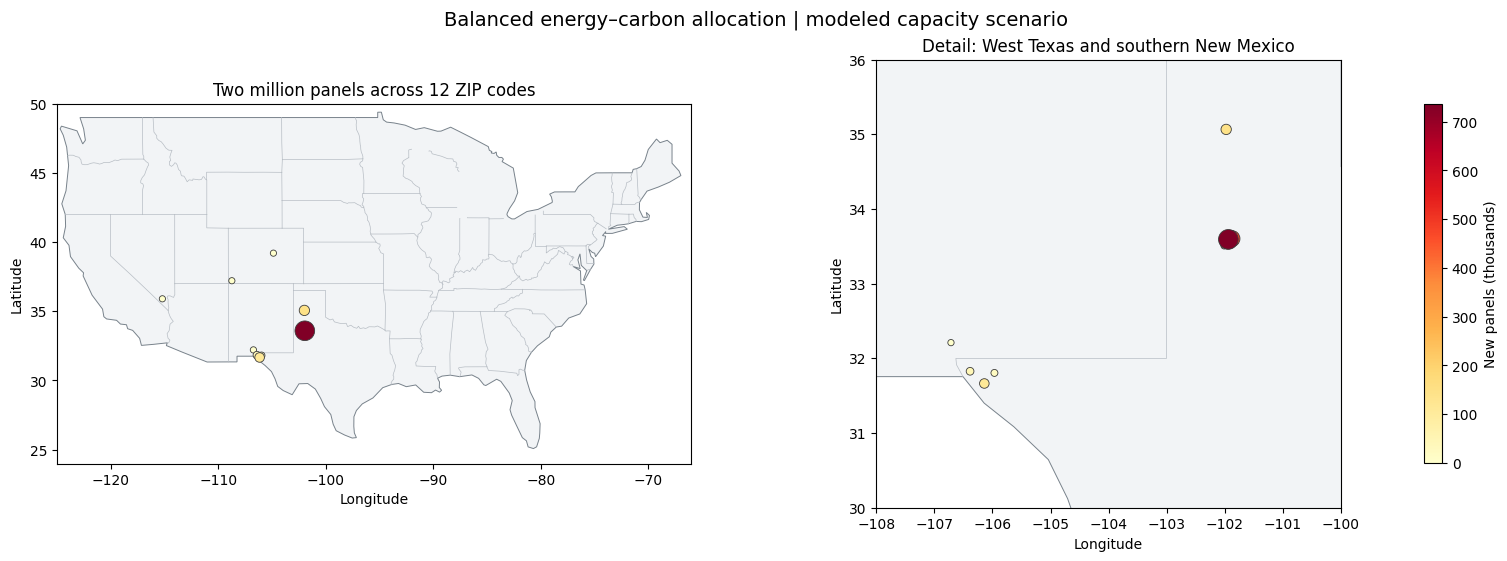

In [23]:
countries = pd.read_json(DATA / "countries.json", typ="series")
borders = pd.read_json(DATA / "state_lines.json", typ="series")

def draw_us_base(ax, countries, borders):
    for feature in countries["features"]:
        if feature["properties"].get("ADM0_A3") == "USA":
            geometry = feature["geometry"]
            polygons = geometry["coordinates"] if geometry["type"] == "MultiPolygon" else [geometry["coordinates"]]

            for polygon in polygons:
                ring = np.asarray(polygon[0])
                ax.fill(ring[:, 0], ring[:, 1], facecolor="#f2f4f6", edgecolor="#78828b", linewidth=0.7, zorder=0)

    for feature in borders["features"]:
        if feature["properties"].get("ADM0_A3") == "USA":
            geometry = feature["geometry"]
            lines = geometry["coordinates"] if geometry["type"] == "MultiLineString" else [geometry["coordinates"]]

            for line in lines:
                xy = np.asarray(line)
                ax.plot(xy[:, 0], xy[:, 1], color="#b7bdc4", linewidth=0.5, zorder=1)

    ax.set_aspect(1 / np.cos(np.deg2rad(39)))
    ax.set(xlabel="Longitude", ylabel="Latitude")

def plot_allocation_map(result, countries, borders):
    placed = result.loc[result["panels"].gt(0)].sort_values("panels")
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), layout="constrained")

    for ax in axes:
        draw_us_base(ax, countries, borders)
        points = ax.scatter(placed["Longitude"], placed["Latitude"], s=20 + 180 * placed["panels"] / placed["panels"].max(), c=placed["panels"] / 1000, cmap="YlOrRd", edgecolors="#3c3c3c", linewidths=0.6, vmin=0, vmax=placed["panels"].max() / 1000, zorder=3)

    axes[0].set(xlim=(-125, -66), ylim=(24, 50), title=f"Two million panels across {len(placed)} ZIP codes")
    axes[1].set(xlim=(-108, -100), ylim=(30, 36), title="Detail: West Texas and southern New Mexico")
    fig.colorbar(points, ax=axes, label="New panels (thousands)", shrink=0.8)
    fig.suptitle("Balanced energy–carbon allocation | modeled capacity scenario", fontsize=14)

    return fig

fig = plot_allocation_map(allocation, countries, borders)
plt.show()

### Results for two million panels

The main capacity scenario contains 9,341 eligible ZIP codes. The selected allocation places exactly 2,000,000 individual panels across 12 ZIP codes.

| Allocation | Energy (GWh/year) | Carbon offset (kt CO₂e/year) | Energy fraction | Carbon fraction |
|:--|--:|--:|--:|--:|
| Energy only | 852.49 | 232.43 | 100.00% | 42.79% |
| Carbon only | 643.71 | 543.14 | 75.51% | 100.00% |
| Equal normalized weights | 771.12 | 521.64 | 90.45% | 96.04% |
| Balanced search | 777.99 | 507.50 | 91.26% | 93.44% |

The balanced search achieves

$$
L_{\mathrm{best}}=0.912605,
$$

while the upper bound is

$$
U=0.917374.
$$

Therefore,

$$
0.912605\leq L^\star\leq0.917374.
$$

The selected allocation is within approximately **0.477 percentage points** of the globally optimal balanced score under the modeled assumptions.

The supporting weight selected by the search is $\alpha=0.780$.

### Placement locations

| ZIP code | State | New panels |
|:--|:--|--:|
| 79119 | Texas | 144,836 |
| 79382 | Texas | 4,486 |
| 79407 | Texas | 464,089 |
| 79415 | Texas | 470,126 |
| 79416 | Texas | 735,581 |
| 79908 | Texas | 44,441 |
| 79928 | Texas | 112,619 |
| 79938 | Texas | 21,504 |
| 80118 | Colorado | 205 |
| 81334 | Colorado | 19 |
| 88047 | New Mexico | 1,950 |
| 89044 | Nevada | 144 |
| **Total** | | **2,000,000** |

The map places markers at ZIP-level coordinates, rather than at individual rooftops. Marker colors indicate thousands of new panels. Marker sizes increase with allocation but include a minimum visible size. Nearby ZIP markers can overlap.

### Interpretation

The energy-only allocation retains only 42.79% of the carbon-only optimum. The carbon-only allocation retains 75.51% of the energy-only optimum. These differences demonstrate why neither single-objective policy fully addresses the question.

Equal normalized weights already produce a strong compromise, retaining 90.45% of the energy optimum and 96.04% of the carbon optimum. The balanced search increases the weaker fraction to 91.26%, while reducing the stronger fraction to 93.44%.

The balanced allocation is therefore better under the max–min criterion, but it does not dominate the equal-weight allocation: it generates more energy while offsetting less carbon.

Because the selected allocation maximizes a weighted sum with strictly positive weights on both objectives, it is Pareto-efficient within the modeled feasible set, apart from numerical precision. An allocation improving one objective without worsening the other would otherwise have a larger weighted score.

### Geographic concentration

Texas receives 1,997,682 panels, approximately 99.88% of the budget. Colorado receives 224, New Mexico receives 1,950, and Nevada receives 144.

This concentration follows from the model's objectives and constraints. It rewards per-panel energy and carbon benefits, but does not reward geographic coverage or enforce demographic equity. High-scoring locations can receive large allocations until their modeled capacities are exhausted.

Consequently, balancing energy and carbon should not be described as balancing geographic or socioeconomic equity. Those would require additional objectives or constraints.

### Capacity sensitivity

The same procedure was repeated after restricting available capacity to smaller fractions of the main scenario. Each scenario recalculates its own single-objective benchmarks.

| Capacity multiplier | ZIPs receiving panels | Energy fraction | Carbon fraction | Balanced fraction |
|:--|--:|--:|--:|--:|
| 1.0 | 12 | 91.26% | 93.44% | 91.26% |
| 0.5 | 14 | 91.82% | 92.07% | 91.82% |
| 0.1 | 51 | 91.87% | 92.22% | 91.87% |

These results show that a strong proportional compromise also exists in the smaller-capacity scenarios. They do not validate the capacity estimates.

The fractions use different scenario-specific denominators, so larger normalized fractions do not necessarily imply larger absolute energy or carbon totals.

### Validation

The implementation was checked for:

- Integer and nonnegative panel allocations.
- An exact total of two million panels.
- Compliance with every modeled ZIP capacity.
- Consistency between allocations and reported objective totals.
- Weighted-greedy optimality on a small instance through exhaustive enumeration.
- Validity of the balanced-score bound against an exhaustively solved small instance.

### Limitations

The optimality bound concerns the mathematical model, not the accuracy of its physical inputs.

The model assumes equal panel costs, fixed average per-panel benefits, and independent ZIP capacity limits. It does not account for roof-level installation batches, marginal roof quality, grid congestion, curtailment, changing displaced generation, financing, or implementation costs.

The remaining-capacity formula is a scenario estimate. It should be replaced with a verified inventory before interpreting the allocation as a deployment recommendation.

The analysis also excludes locations without usable coordinates and restricts the study region to the contiguous US. Its conclusions therefore concern the eligible dataset, rather than every possible US rooftop.

### Relationship to the papers

Paper 1 motivates capacity-constrained siting and compares energy-oriented, carbon-oriented, equity-oriented, and round-robin strategies. Paper 2 formalizes the multi-objective allocation problem and studies Pareto-efficient trade-offs.

This analysis adopts their central energy–carbon siting question while defining an explicit max–min compromise criterion and deriving an accompanying optimality bound.

It uses its own individual-panel units and stated capacity scenario. The reported numbers are not an exact replication of either paper's experiments.

### References

1. Sigrist et al. (2025). *Lost in Siting: The Hidden Carbon Cost of Inequitable Residential Solar Installations*. Sections 4 and 6. https://doi.org/10.1145/3679240.3734603

2. Sigrist et al. (2025). *Multi-objective Evolutionary Learning for Near Pareto-Optimal Optimization of Solar Deployment*. Sections 3.3, 4.1, and 4.2. https://doi.org/10.1145/3736425.3770115

3. Natural Earth. Map boundary data. https://www.naturalearthdata.com/

In [24]:
sensitivity_rows = []

for scale in [1.0, 0.5, 0.1]:
    scenario_sites = prepare_sites(raw, capacity_scale=scale)
    scenario_allocation, scenario_summary, scenario_certificate = balanced_allocation(scenario_sites, n=2_000_000)
    row = scenario_summary.loc["Balanced search"]

    sensitivity_rows.append({
        "Capacity multiplier": scale,
        "ZIPs used": int(row["ZIPs used"]),
        "Energy fraction (%)": 100 * row["Energy fraction"],
        "Carbon fraction (%)": 100 * row["Carbon fraction"],
        "Balanced fraction (%)": 100 * row["Minimum fraction"],
        "Gap bound (percentage points)": 100 * scenario_certificate["absolute_gap"]
    })

sensitivity = pd.DataFrame(sensitivity_rows).set_index("Capacity multiplier")
print(sensitivity.round(4).to_string())

                     ZIPs used  Energy fraction (%)  Carbon fraction (%)  Balanced fraction (%)  Gap bound (percentage points)
Capacity multiplier                                                                                                           
1.0                         12              91.2605              93.4382                91.2605                         0.4769
0.5                         14              91.8165              92.0698                91.8165                         0.0557
0.1                         51              91.8707              92.2226                91.8707                         0.1200


# EX 3. Use the Sunsight library to create a projection of the success of your model in Carbon Offset and Energy Generation (like fig 6 + 7 in paper 1) compared to the baselines of the paper. 

### SunSight projections against the paper's baselines

### The question : 

How do the additional annual energy generation and carbon offset of our Question 2 policy compare with the baseline strategies described in Paper 1 as the number of deployed panels increases?

The comparison uses a common study sample, individual-panel units, capacity scenario, and evaluation procedure for every strategy.

This is a controlled re-evaluation of the paper's policy ideas under our stated assumptions. It is not an exact numerical replication of Figures 6 and 7.

### Projection quantities

Let $a_i(n)$ be the number of additional panels assigned to ZIP code $i$ after deploying a total of $n$ panels.

Using the per-panel benefits from Question 2,

$$
e_i=\frac{T_i}{P_i},
\qquad
c_i=\frac{B_i}{P_i},
$$

the additional annual benefits are

$$
E(n)=\sum_i a_i(n)e_i,
$$

$$
C(n)=\sum_i a_i(n)c_i.
$$

Energy is measured in kWh per year, and carbon offset in metric tons CO₂e per year. The plots convert these to GWh per year and kilotons CO₂e per year.

These are benefits from newly allocated panels only. Existing-fleet generation and historical emissions savings are not added to the curves.

The horizontal axis is panel count, not calendar time. A curve therefore does not specify when installations occur or integrate their benefits across multiple years.

### Common study conditions

All strategies use the 9,341 eligible ZIP codes and modeled capacities from Question 2:

$$
u_i=
\left\lfloor
P_i\left(1-\frac{I_i}{Q_i}\right)
\right\rfloor.
$$

This remains a capacity scenario, not a verified inventory of remaining individual-panel space.

All strategies satisfy the same capacity limits. The analysis uses checkpoints

$$
n\in\{0,100000,200000,\ldots,2000000\}.
$$

The checkpoint at 1.8 million panels corresponds to the maximum deployment budget used in Paper 1. The final two checkpoints extend the comparison to the two-million-panel allocation from Question 2.

### Baseline strategies

The baseline policies follow Section 4 of Paper 1.

| Policy | Allocation rule |
|:--|:--|
| Status quo | Allocate in proportion to existing rooftop-installation counts, redistributing shares when modeled capacities are reached. |
| Energy-efficient | Fill ZIP capacities in descending order of per-panel energy potential. |
| Carbon-efficient | Fill ZIP capacities in descending order of per-panel carbon potential. |
| Racial-equity-aware | Fill ZIP capacities in descending order of Black population proportion. |
| Income-equity-aware | Fill ZIP capacities in ascending order of median income. |
| Round robin | Alternate panel assignments among the energy, carbon, racial, and income rankings, respecting shared capacities. |

Population-proportional placement is not one of the Section 4 baselines and is not included.

The demographic policies prioritize their specified demographic attributes. Their names do not establish that they optimize every possible definition of equity.

### Status-quo interpretation

Existing installation counts represent rooftop systems or buildings, rather than individual panels. Their shares are used as a proxy for future panel-placement shares.

The capacity-constrained proportional allocation can be written as

$$
a_i(n)=\min\left(u_i,\lambda(n)I_i\right),
$$

where $\lambda(n)$ is chosen so that

$$
\sum_i a_i(n)=n.
$$

ZIP codes with zero existing installations receive zero weight under this continuation-of-existing-patterns baseline.

The allocation is fractional and represents an expected or divisible allocation, not a particular integer realization. This is appropriate for evaluating its expected linear energy and carbon outcomes:

$$
\mathbb{E}[E(A)]=E(\mathbb{E}[A]),
\qquad
\mathbb{E}[C(A)]=C(\mathbb{E}[A]).
$$

No stochastic simulation or uncertainty interval is implied by this expectation calculation.

### Capacity-safe round robin

At each turn, one of the four rankings selects its highest-ranked ZIP with unused capacity. One panel is assigned there, and the next ranking takes its turn.

All rankings share the same remaining-capacity inventory. If several rankings select the same ZIP, their combined assignments cannot exceed its capacity.

The implementation batches complete cycles when the selected ZIPs remain unchanged. This accelerates the calculation without changing the panel-by-panel allocation rule.

This is an explicit capacity-safe implementation of the round-robin policy idea. It is not a claim of identical behavior to every historical toolkit implementation.

### Our model: freeze the Question 2 policy

Question 2 selected a supporting weight $\hat{\alpha}=0.780$ for a target budget of two million panels.

The projection retains that weight and its two-million-panel normalizers:

$$
s_i=
\hat{\alpha}\frac{e_i}{E^\star(2000000)}
+
(1-\hat{\alpha})\frac{c_i}{C^\star(2000000)}.
$$

For each checkpoint, panels are allocated in descending order of this fixed score.

Consequently, earlier placements remain in place as the deployment budget increases:

$$
a_i(n_2)\geq a_i(n_1)
\qquad
\text{for } n_2\geq n_1.
$$

At two million panels, this produces the exact Question 2 allocation.

The Question 2 optimality-gap statement applies to that final-budget optimization. It does not establish that the frozen policy maximizes the balanced criterion at every smaller checkpoint.

### Use of SunSight

The calculation uses SunSight's actual:

- `Objective` class.
- `calc_obj_by_picked` evaluation function.
- `create_greedy_projection` routine.
- `Projection` class and interpolation method.

The repository is pinned to commit:

`99588d1696c980075a19abf087c669ae5aa22e4e`

A separate adapter supplies our per-panel energy, per-panel carbon, and modeled capacities to the library.

The toolkit's greedy routine reads its capacity limit from `count_qualified`. In the temporary adapter frame only, that column is assigned our modeled individual-panel capacity. The original data and true suitable-building counts remain unchanged.

The status-quo and round-robin allocators are implemented separately to enforce the common capacity constraints. Their outcomes are evaluated using the same SunSight objectives.

### Interpretation of the curves

A larger vertical value means greater additional annual benefit at the same panel count.

The energy-efficient strategy is an upper benchmark for energy generation under the common linear model. The carbon-efficient strategy is the corresponding upper benchmark for carbon offset.

Our policy should therefore be evaluated as a compromise, rather than expected to exceed each single-objective optimizer on its own objective.

The lines join evaluated checkpoints. They do not imply additional simulation at every intermediate panel count.

In [25]:
# SunSight toolkit, vendored at the pinned commit (see Utils/paths.py)

from Simulation.projections_util import Projection, Objective, calc_obj_by_picked, create_greedy_projection

In [26]:
# Capacity constrained status quo

def proportional_allocation(weights, capacities, n):
    weights = np.asarray(weights, dtype=float)
    capacities = np.asarray(capacities, dtype=float)
    allocation = np.zeros(len(weights))
    active = (weights > 0) & (capacities > 0)

    if n > capacities[active].sum():
        raise ValueError("Insufficient capacity among ZIPs with positive status-quo weights.")

    remaining = float(n)

    while remaining > 1e-7:
        shares = remaining * weights[active] / weights[active].sum()
        allocation[active] += np.minimum(shares, capacities[active] - allocation[active])
        remaining = n - allocation.sum()
        active = (weights > 0) & (capacities - allocation > 1e-8)

    return allocation

In [27]:
# Capacity safe round robin

def round_robin_allocation(orders, capacities, n):
    allocation = np.zeros(len(capacities), dtype=np.int64)
    pointers = np.zeros(len(orders), dtype=int)
    remaining = int(n)

    while remaining:
        heads = []
        for k, order in enumerate(orders):
            while allocation[order[pointers[k]]] == capacities[order[pointers[k]]]:
                pointers[k] += 1
            heads.append(order[pointers[k]])

        chosen, multiplicities = np.unique(heads, return_counts=True)
        cycles = min(remaining // len(orders), int(np.min((capacities[chosen] - allocation[chosen]) // multiplicities)))

        if cycles:
            allocation[chosen] += cycles * multiplicities
            remaining -= cycles * len(orders)
        else:
            for k, order in enumerate(orders):
                if remaining == 0:
                    break
                while allocation[order[pointers[k]]] == capacities[order[pointers[k]]]:
                    pointers[k] += 1
                allocation[order[pointers[k]]] += 1
                remaining -= 1
    return allocation

In [28]:
# Evaluate allocations through SunSight

def projection_from_allocations(frame, budgets, allocations, name, objectives):
    curves = {objective.name: {} for objective in objectives}
    for n, allocation in zip(budgets, allocations):
        placements = {zipcode: float(count) for zipcode, count in zip(frame["region_name"], allocation) if count > 0}
        for objective in objectives:
            curves[objective.name][int(n)] = objective.calc(frame, placements)
    return Projection(curves, placements, name)

In [29]:
# Construct all seven projections

def build_projections(raw, max_panels=2_000_000, interval=100_000):
    sites = prepare_sites(raw)
    metadata = raw[["region_name", "Median_income", "black_prop"]]
    sites = sites.merge(metadata, on="region_name", validate="one_to_one")

    if sites[["Median_income", "black_prop"]].isna().any().any() or not sites["Median_income"].gt(0).all() or not sites["black_prop"].between(0, 1).all():
        raise ValueError("Baseline demographics must be valid for the common study sample.")

    result, summary, certificate = balanced_allocation(sites, n=max_panels)

    capacities = sites["capacity"].to_numpy(dtype=np.int64)
    energy = sites["energy"].to_numpy()
    carbon = sites["carbon"].to_numpy()

    energy_max = energy @ greedy_allocation(energy, capacities, max_panels)
    carbon_max = carbon @ greedy_allocation(carbon, capacities, max_panels)
    sites["balanced_score"] = certificate["alpha"] * energy / energy_max + (1 - certificate["alpha"]) * carbon / carbon_max

    frame = sites.copy()
    frame["region_name"] = frame["zip"]
    frame["count_qualified"] = frame["capacity"]

    objectives = [
        Objective("Energy", calc_obj_by_picked, metric="energy"),
        Objective("Carbon", calc_obj_by_picked, metric="carbon")
    ]

    definitions = [
        ("Energy-efficient", "energy", False),
        ("Carbon-efficient", "carbon", False),
        ("Racial-equity-aware", "black_prop", False),
        ("Income-equity-aware", "Median_income", True),
        ("Balanced (fixed ranking)", "balanced_score", False)
    ]

    projections = [create_greedy_projection(frame.copy(), n_panels=max_panels, sort_by=key, ascending=ascending, objectives=objectives, name=name) for name, key, ascending in definitions]

    for projection in projections:
        for objective in objectives:
            projection.objective_projections[objective.name][0] = 0.0

    budgets = np.arange(0, max_panels + 1, interval, dtype=int)

    if budgets[-1] != max_panels:
        budgets = np.append(budgets, max_panels)

    status_quo = [proportional_allocation(sites["existing_installs_count"], capacities, int(n)) for n in budgets]

    ranking_values = [energy, carbon, sites["black_prop"].to_numpy(), -sites["Median_income"].to_numpy()]
    orders = [np.argsort(-values, kind="stable") for values in ranking_values]
    round_robin = [round_robin_allocation(orders, capacities, int(n)) for n in budgets]

    projections.insert(0, projection_from_allocations(frame, budgets, status_quo, "Status quo", objectives))
    projections.insert(5, projection_from_allocations(frame, budgets, round_robin, "Round robin (capacity-safe)", objectives))

    return sites, result, projections, budgets, certificate

projection_sites, final_allocation, projections, projection_budgets, projection_certificate = build_projections(raw)
projection_curves = {projection.name: projection.interpolateIntervalObjectiveProjections(interval=100_000) for projection in projections}

In [30]:
# Report outcomes at the two endpoint budgets

def projection_summary(curves, n):
    baseline = curves["Status quo"].loc[n]
    rows = []

    for name, curve in curves.items():
        values = curve.loc[n]
        rows.append({
            "Policy": name,
            "Energy (GWh/year)": values["Energy"] / 1_000_000,
            "Carbon (kt CO2e/year)": values["Carbon"] / 1000,
            "Energy vs status quo (%)": 100 * (values["Energy"] / baseline["Energy"] - 1),
            "Carbon vs status quo (%)": 100 * (values["Carbon"] / baseline["Carbon"] - 1)
        })

    return pd.DataFrame(rows).set_index("Policy")

print("Results at 1.8 million panels:")
print(projection_summary(projection_curves, 1_800_000).round(4).to_string())

print("\nResults at 2 million panels:")
print(projection_summary(projection_curves, 2_000_000).round(4).to_string())

ours = projection_curves["Balanced (fixed ranking)"]
status_quo = projection_curves["Status quo"]
positive_budgets = ours.index > 0
dominates = ours.loc[positive_budgets].ge(status_quo.loc[positive_budgets]).all(axis=1)

print(f"\nOur policy matches or exceeds status quo on both objectives at {int(dominates.sum())} of {len(dominates)} positive evaluated budgets.")

Results at 1.8 million panels:
                             Energy (GWh/year)  Carbon (kt CO2e/year)  Energy vs status quo (%)  Carbon vs status quo (%)
Policy                                                                                                                   
Status quo                            641.3871               246.0334                    0.0000                    0.0000
Energy-efficient                      767.5300               209.2622                   19.6672                  -14.9456
Carbon-efficient                      579.4296               488.9053                   -9.6599                   98.7150
Racial-equity-aware                   578.6839               361.2183                   -9.7762                   46.8167
Income-equity-aware                   568.9198               372.1180                  -11.2985                   51.2469
Round robin (capacity-safe)           625.5704               360.2262                   -2.4660                   4

In [31]:
# Consistency checks

capacity_by_zip = projection_sites.set_index("zip")["capacity"]

for projection in projections:
    assert np.isclose(sum(projection.panel_placements.values()), 2_000_000)
    assert all(count >= 0 for count in projection.panel_placements.values())
    assert all(count <= capacity_by_zip.loc[zipcode] + 1e-6 for zipcode, count in projection.panel_placements.items())

for curve in projection_curves.values():
    assert np.allclose(curve.loc[0], 0)
    assert (np.diff(curve.to_numpy(), axis=0) >= -1e-6).all()
    assert (curve["Energy"] <= projection_curves["Energy-efficient"]["Energy"] + 1e-6).all()
    assert (curve["Carbon"] <= projection_curves["Carbon-efficient"]["Carbon"] + 1e-6).all()

balanced_projection = next(projection for projection in projections if projection.name == "Balanced (fixed ranking)")
projected_counts = np.array([balanced_projection.panel_placements.get(zipcode, 0) for zipcode in projection_sites["zip"]])

assert np.array_equal(projected_counts, final_allocation["panels"].to_numpy())

print("Budget, capacity, monotonicity, single-objective bounds, and final-allocation checks passed.")

Budget, capacity, monotonicity, single-objective bounds, and final-allocation checks passed.


### Findings and interpretation

At 1.8 million additional panels, corresponding to the endpoint in Paper 1, the results are:

| Strategy | Additional energy (GWh/year) | Additional carbon offset (kt CO₂e/year) |
|:--|--:|--:|
| Status quo | 641.39 | 246.03 |
| Energy-efficient | 767.53 | 209.26 |
| Carbon-efficient | 579.43 | 488.91 |
| Racial-equity-aware | 578.68 | 361.22 |
| Income-equity-aware | 568.92 | 372.12 |
| Round robin, capacity-safe | 625.57 | 360.23 |
| Our balanced fixed-ranking policy | 700.98 | 455.40 |

Relative to status quo, our policy achieves

$$
100\left(\frac{700.978463}{641.387112}-1\right)
\approx 9.29\%
$$

more additional annual energy generation, and

$$
100\left(\frac{455.399721}{246.033411}-1\right)
\approx 85.10\%
$$

more additional annual carbon offset.

At two million panels, our policy produces **777.99 GWh/year** and **507.50 kt CO₂e/year**, matching the Question 2 result. The corresponding improvements over status quo are approximately **9.17%** and **85.64%**.

Our policy matches or exceeds status quo on both objectives at all 20 positive evaluated budgets. This statement concerns the sampled checkpoints, not an independently verified comparison at every possible intermediate panel count.

### What the comparison demonstrates

The energy-efficient policy generates the most energy but performs poorly on carbon offset relative to status quo. This illustrates the distinction between maximizing electricity output and maximizing avoided emissions.

The carbon-efficient policy provides the largest carbon offset but sacrifices energy generation. Our policy lies between these single-objective extremes and exceeds status quo on both metrics in this scenario.

The round-robin and demographic policies improve carbon outcomes relative to status quo, but their energy generation is lower. Our policy performs better on both plotted outcomes than these policies at 1.8 million panels. However, these two plots do not evaluate demographic equity. They cannot establish that our policy is better on the complete set of objectives considered by the papers.

### Why several curves are approximately linear

The model assigns fixed average energy and carbon benefits to each panel within a ZIP. Until a capacity boundary changes the selected locations, each additional panel has similar modeled benefits.

Approximately straight curves therefore reflect the model's constant-marginal-benefit assumptions. They are not evidence that actual solar deployment, electricity generation, or grid decarbonization will evolve linearly over calendar time.

### Why these percentages differ from Paper 1

The paper reports results under its own data preparation, unit conventions, capacities, and implementation choices.

Our comparison retains the individual-panel units and explicit remaining-capacity scenario established in Question 2. It also uses a common eligible sample and a capacity-safe interpretation of proportional and round-robin placement.

Therefore, the reported 85.10% carbon improvement is a new result within our scenario. It should not be presented as a replication of the paper's reported improvement percentages.

Calendar-year and net-zero reference lines are omitted because converting our individual-panel counts into those milestones would require additional assumptions about existing installed panel capacity and future deployment timing.

### Limitations

The projection evaluates a deterministic planning scenario, not a calibrated forecast of future adoption.

Its main limitations are:

- Remaining capacity is estimated rather than independently verified.
- Average technical yields may differ from the marginal yields of the next available roofs.
- Carbon-offset factors remain fixed as deployment increases.
- Costs, financing, grid constraints, curtailment, and adoption behavior are not modeled.
- Existing rooftop-system shares are a proxy for status-quo future panel shares.
- Geographic and demographic equity are not evaluated by these two output curves.

The fixed ranking was chosen for the two-million-panel planning target. Its performance at smaller budgets is a consequence of following that deployment path, rather than a separate optimality guarantee at those budgets.

### Validation

The calculation checks conservation of the deployment budget, common capacity constraints, zero additional benefit at zero additional panels, and nondecreasing objective totals.

It also verifies that no strategy exceeds the corresponding single-objective optimizer and that the final frozen-ranking allocation exactly matches Question 2.

Separately, the batched round-robin implementation was checked against a literal panel-by-panel implementation on small examples. The proportional allocator was checked for capacity compliance, budget conservation, and nested expected allocations.

### References

1. Sigrist et al. (2025). *Lost in Siting: The Hidden Carbon Cost of Inequitable Residential Solar Installations*. Sections 4–6 and Figures 6–7. https://doi.org/10.1145/3679240.3734603

2. SunSight, pinned source version. https://github.com/coopersigrist/SunSight/tree/99588d1696c980075a19abf087c669ae5aa22e4e

3. SunSight projection and objective implementation. https://github.com/coopersigrist/SunSight/blob/99588d1696c980075a19abf087c669ae5aa22e4e/Simulation/projections_util.py

# EX 4. Using the SunSight library replicate the results from the second paper (EVA implementation), namely fig 3 + 4

### EVA reconstruction and reproduction audit

### Reproduction objective

This experiment reconstructs the EVA workflow described in Paper 2 and generates the two requested figure types:

- Figure 3: four objective values expressed as ratios to status quo across installation budgets.
- Figure 4: a map of ZIP-level scores produced by the scoring network.

The experiment uses pinned SunSight data/configuration, its objective and projection interfaces, and NEAT-Python genome operations.

It is a documented methodological reconstruction. Exact numerical reproduction of the published figures is not established.

### Features and scoring network

The five measured attributes are:

1. Median income.
2. Carbon-offset potential per panel.
3. Solar-resource potential.
4. Stored panel utilization.
5. Black population proportion.

Each attribute is min-max normalized:

$$
\widetilde{x}_{ij}
=
\frac{x_{ij}-\min_\ell x_{\ell j}}
{\max_\ell x_{\ell j}-\min_\ell x_{\ell j}}.
$$

The released configuration expects six numerical inputs because the example data-processing pipeline adds a constant leading input:

$$
z_i=
\left[
1,\widetilde{x}_{i1},\ldots,\widetilde{x}_{i5}
\right].
$$

The constant is not a sixth measured attribute.

The network produces a score

$$
s_i=V_\theta(z_i).
$$

ZIP codes are ranked by descending score. Installation units are assigned in that order until the budget is exhausted, respecting the selected capacity convention.

### Reporting conventions

For this separate reproduction experiment, the linear objectives use the released toolkit indicators:

$$
f_{\mathrm{CO}}(a)
=
\sum_i a_i\,\mathrm{carbon\_offset\_kg\_per\_panel}_i,
$$

$$
f_{\mathrm{EG}}(a)
=
\sum_i a_i\,\mathrm{yearly\_sunlight\_kwh\_kw\_threshold\_avg}_i.
$$

The legacy toolkit allocation cap is `count_qualified`.

These conventions are retained for comparison with the released implementation. They are not reinterpreted as a verified inventory of remaining individual-panel capacity, and the energy indicator is not substituted for the physical per-panel calculation used in Questions 2–3.

The results are reported as dimensionless ratios rather than physical energy totals.

### Equity objectives

Section 6.2 describes evaluating the installation mix after new installations are added. Accordingly, the main reconstruction evaluates equity using existing-plus-new counts:

$$
b_i=I_i+a_i,
$$

where $I_i$ is the existing installation count and $a_i$ is the new assignment.

Let $H_I$ and $L_I$ denote above- and below-median income groups, and let $H_R$ and $L_R$ denote groups with higher and lower Black population proportions. Median ties are assigned to the high group.

The count-balance objectives are

$$
f_{\mathrm{IE}}(a)
=
1-
\frac{
\left|
\sum_{i\in H_I}b_i-\sum_{i\in L_I}b_i
\right|
}{
\sum_i b_i
},
$$

$$
f_{\mathrm{RE}}(a)
=
1-
\frac{
\left|
\sum_{i\in H_R}b_i-\sum_{i\in L_R}b_i
\right|
}{
\sum_i b_i
}.
$$

These scores lie between zero and one. They measure balance between ZIP groups, not the income or race of individual solar owners.

Evaluating only new installations would define a different experiment.

### Composite Performance Ratio

For each objective $k$, define its ratio to status quo at the same installation budget:

$$
r_k(a)=\frac{f_k(a)}{f_k(a^{SQ})}.
$$

The Composite Performance Ratio is

$$
CPR(a)=\sum_{k=1}^{4}r_k(a).
$$

A CPR greater than four does not imply improvement on every objective. A strong improvement in one objective can compensate numerically for deterioration in another.

### Evolutionary reconstruction

The principal settings follow the paper:

| Setting | Value |
|:--|:--|
| Population size | 30 |
| Generations per training run | 6 |
| Training installation budget | 2,000,000 |
| Survival target | 0.3 |
| Elite retained | 1 |

For objective selectivities $v_k$, each sequential objective filter retains approximately

$$
s_k=0.3^{v_k/\sum_jv_j}
$$

of the current survivors.

Objectives are randomly ordered. After filtering, survivors are ranked by CPR. Twenty-nine distinct selected-parent pairs produce mutated offspring, and one selected elite is retained.

The reconstruction uses a global selected-parent pool. It does not reproduce NEAT-Population speciation or execute the released binary-fitness training wrapper unchanged. Mutation and crossover use NEAT-Python genome operations and the pinned source configuration.

The best selected CPR checkpoint observed during a run is retained.

Selectivity starts at one for every objective. If an objective falls below baseline, its selectivity is increased according to the paper's tuning principle:

$$
v_k^{\mathrm{next}}
=
\frac{v_k}{r_k},
\qquad r_k<1.
$$

The reconstruction permits at most six tuning rounds. All three reported seeds passed the endpoint comparison in the first round.

Seed 0 is the predeclared primary run. Seeds 1 and 2 are sensitivity checks, not candidates selected for resemblance to the published figure.

### Status-quo reconstruction

Paper 2 describes a March 2024–March 2025 EIA-based baseline. The bundled monthly series stops at February 2025, while its helper uses January residential capacity.

The supplementary table therefore comes from EIA's archived May 2025 Electric Power Monthly, Table 6.2.B: estimated small-scale photovoltaic capacity, all sectors, for March 2025 and March 2024.

This is an explicit reconstruction choice. The precise historical extraction used for the published figures is not identified.

State growth shares are combined with within-state existing-installation shares.

The following data decisions are documented:

- Negative net changes in Rhode Island and Missouri are clipped to zero.
- Alabama is excluded because its estimates are marked NM, meaning not meaningful due to large relative standard error.
- Shares are redistributed within states where the legacy allocation cap binds.
- The resulting study sample contains 10,243 ZIP codes.

Missing coordinates do not prevent a ZIP from participating in training. Only locations with usable contiguous-US coordinates are displayed on the map.

### Reproduction checks

The implementation checks:

- Installation-budget conservation.
- Capacity compliance.
- Equity values within their mathematical bounds.
- Agreement between batched inference and native network activation.
- Identical resulting allocations from the two inference methods.

The experiment also replays an explicitly identified released checkpoint and compares the paper-equation reconstruction with the toolkit's native objective calculations.

In [32]:
# Preaparing the experiment

from q4_eva import OBJECTIVES, prepare_experiment, train_with_tuning, eva_projections, network_scores, rank_allocation, baseline_allocation, evaluate

eia = pd.read_csv(DATA / "Q4_EIA_March_2024_2025.csv")
experiment = prepare_experiment(raw, eia)

print("Eligible ZIP codes:", len(experiment["data"]))

Eligible ZIP codes: 10243


In [33]:
# Training the seeded runs

networks = {}
endpoint_rows = []

for seed in [0, 1, 2]:
    network, tuning_log, generation_log = train_with_tuning(experiment, NEAT_CONFIG, seed=seed)
    networks[seed] = network
    model_projection, baseline_projection, ratios, scores = eva_projections(experiment, network)
    endpoint_rows.append([seed, *ratios.loc[2_000_000], int(ratios.ge(1).all(axis=1).sum())])

endpoint_summary = pd.DataFrame(endpoint_rows, columns=["Seed", *OBJECTIVES, "Budgets dominating all objectives"])
print(endpoint_summary.round(4).to_string(index=False))

model_projection, baseline_projection, ratios, scores = eva_projections(experiment, networks[0])

 Seed  Carbon  Energy  Racial equity  Income equity  Budgets dominating all objectives
    0  1.2880  1.1944         1.0218         1.3901                                  7
    1  1.5972  1.0191         1.1279         1.5435                                 14
    2  1.5779  1.0369         1.1352         1.5609                                 16


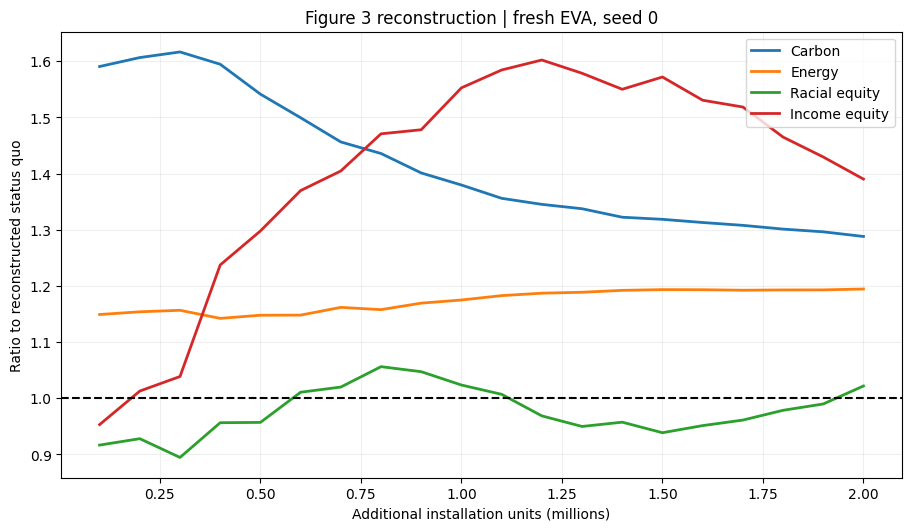

In [34]:
# Figure 3

fig, ax = plt.subplots(figsize=(9, 5.2), layout="constrained")

for name in OBJECTIVES:
    ax.plot(ratios.index / 1_000_000, ratios[name], label=name, linewidth=2)

ax.axhline(1, color="black", linestyle="--")
ax.set(xlabel="Additional installation units (millions)", ylabel="Ratio to reconstructed status quo", title="Figure 3 reconstruction | fresh EVA, seed 0")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

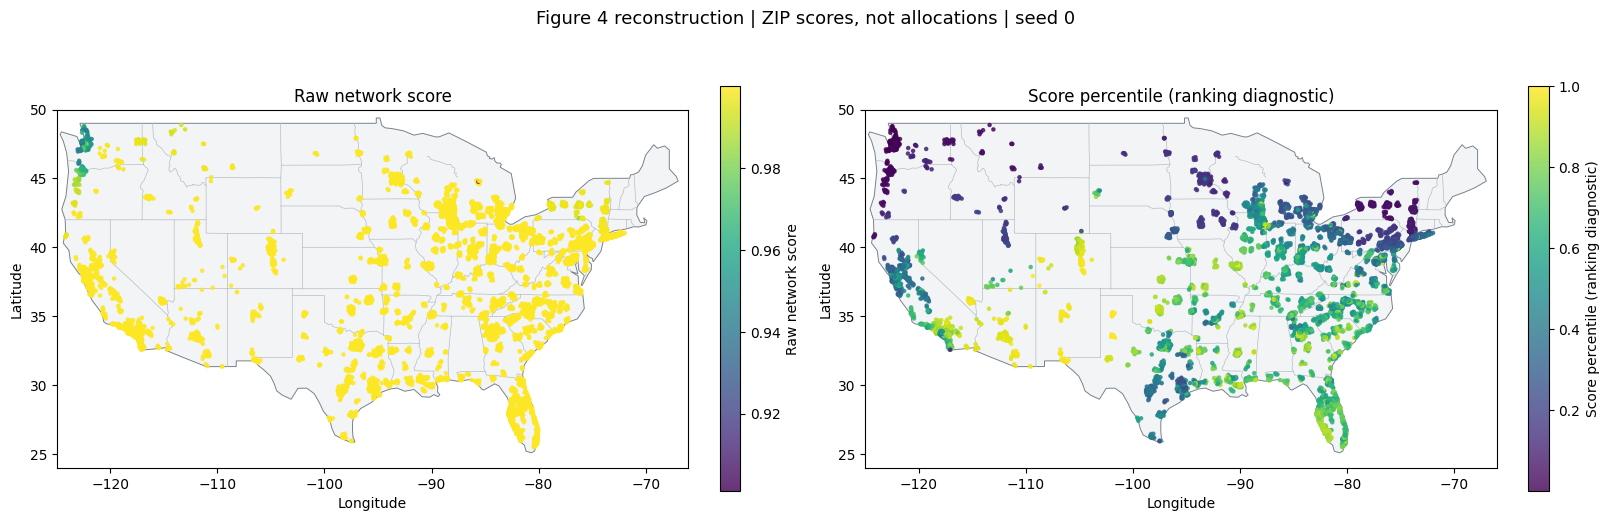

In [35]:
# Figure 4

data = experiment["data"]
valid = data["Latitude"].between(24, 50) & data["Longitude"].between(-125, -66)
percentiles = pd.Series(scores).rank(pct=True).to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.4), layout="constrained")

for ax, values, label in zip(axes, [scores, percentiles], ["Raw network score", "Score percentile (ranking diagnostic)"]):
    draw_us_base(ax, countries, borders)
    points = ax.scatter(data.loc[valid, "Longitude"], data.loc[valid, "Latitude"], c=values[valid], s=5, cmap="viridis", alpha=0.8, zorder=3)
    fig.colorbar(points, ax=ax, label=label, shrink=0.8)
    ax.set(xlim=(-125, -66), ylim=(24, 50), title=label)

fig.suptitle("Figure 4 reconstruction | ZIP scores, not allocations | seed 0", fontsize=13)
plt.show()

In [36]:
# Validation

for n in ratios.index:
    allocation = rank_allocation(scores, experiment["capacity"], int(n))
    baseline = baseline_allocation(experiment, int(n))

    assert allocation.sum() == n
    assert np.isclose(baseline.sum(), n)
    assert (allocation >= 0).all() and (allocation <= experiment["capacity"]).all()
    assert (baseline >= 0).all() and (baseline <= experiment["capacity"] + 1e-6).all()

    equity = evaluate(experiment, allocation)[2:]
    assert ((equity >= 0) & (equity <= 1)).all()

native_scores = np.array([networks[0].activate(row)[0] for row in experiment["inputs"]])

assert np.allclose(native_scores, scores, atol=1e-14, rtol=0)
assert np.array_equal(rank_allocation(native_scores, experiment["capacity"], 2_000_000), rank_allocation(scores, experiment["capacity"], 2_000_000))

print("Budget, capacity, equity bounds, and native-inference checks passed.")

Budget, capacity, equity bounds, and native-inference checks passed.


In [37]:
# Auditing a released checkpoint

import pickle

released_path = SUNSIGHT / "Models/Neat/models/05-31-25/NEAT_model_lexicase_weighted_5.pkl"

with released_path.open("rb") as stream:
    released_network = pickle.load(stream)

released_scores = network_scores(released_network, experiment["inputs"])
released_allocation = rank_allocation(released_scores, experiment["capacity"], 2_000_000)
reference = baseline_allocation(experiment, 2_000_000)

released_ratios = evaluate(experiment, released_allocation) / evaluate(experiment, reference)
print(pd.Series(released_ratios, index=OBJECTIVES).round(4))

Carbon           1.5773
Energy           0.9730
Racial equity    0.8354
Income equity    1.0730
dtype: float64


# Findings and how reproduction worked out

### Results

The fresh primary run, seed 0, produces the following ratios at two million additional installation units:

| Objective | Ratio to reconstructed status quo | Change |
|:--|--:|--:|
| Carbon | 1.2880 | +28.80% |
| Energy | 1.1944 | +19.44% |
| Racial equity | 1.0218 | +2.18% |
| Income equity | 1.3901 | +39.01% |

All three seeded runs improve the four endpoint objectives. However, none meets all four baselines at every evaluated deployment budget.

Seed 0 meets all four baselines at seven of twenty budgets; seeds 1 and 2 do so at fourteen and sixteen budgets, respectively.

These three runs demonstrate sensitivity to evolutionary randomness. They are not enough to establish a precise performance distribution or confidence interval.

### Training-budget performance versus deployment-path performance

The training evaluation uses two million installation units. Figure 3 evaluates prefixes of the resulting ranking at smaller budgets.

An allocation can have favorable demographic balance at the final budget while its earlier placements are concentrated in one group. Therefore, endpoint success does not guarantee success throughout the deployment path.

The paper's reported improvement on all objectives across evaluated budgets is not reproduced by this experiment.

### What the scoring map means

Figure 4 displays the network's ZIP-level scores, not the number of installations assigned to each location.

The score is not a probability, a predicted carbon quantity, or a calibrated measure of confidence. Its ordering determines which locations are selected first.

The percentile panel makes this ordering easier to inspect when raw sigmoid outputs are compressed near their upper limit. It is clearly labeled as a ranking diagnostic and does not change the allocation.

ZIP codes without usable coordinates remain eligible for training but are omitted from the map. Blank map areas should not be interpreted as zero scores.

### Model inspection

The primary seed-0 network contains one sigmoid output and no hidden nodes. Because sigmoid is monotonically increasing, its ranking is equivalent to a linear combination of the retained normalized inputs.

NEAT permits more complex network structures, but this run does not demonstrate a benefit from learned nonlinear ranking structure.

### Differences between the paper and released implementation

The released `calc_equity` function does not implement the same count-balance formula used in this reconstruction.

It updates a density based on existing-plus-new installation counts divided by potential-panel counts, then calculates a quantity of the form

$$
2-\frac{|\bar{u}_H-\bar{u}_L|}{\bar{u}}.
$$

That differs from the aggregate count-balance equations in Section 4.2. The two metrics must not be silently interchanged.

The released configuration has six numerical inputs, while the paper describes five measured attributes. The example preprocessing supplies the additional constant input, which this reconstruction preserves.

The global selection and reproduction adapter follows the paper's described truncation and CPR logic. It does not reproduce the released training wrapper unchanged or implement NEAT-Population speciation. This is a methodological reconstruction rather than a bit-for-bit replay of the author's training environment.

The released baseline helper uses January residential-capacity data, whereas the paper describes March-to-March small-scale PV growth. The archived March table used here is a documented reconstruction, not a verified copy of the authors' exact extraction.

### A mathematical check on comparability

For our reconstructed two-million-installation baseline, racial equity is approximately

$$
f_{\mathrm{RE}}(a^{SQ})=0.8802.
$$

Because the count-balance objective cannot exceed one,

$$
\frac{f_{\mathrm{RE}}(a)}{f_{\mathrm{RE}}(a^{SQ})}
\leq
\frac{1}{0.8802}
\approx 1.1361.
$$

The paper's approximately 1.24 reported racial-equity ratio therefore cannot be obtained under this exact reconstructed denominator and objective definition.

This demonstrates that the evaluation conditions differ. It does not, by itself, establish an error in the paper.

### Conclusion

The experiment reproduces the broad scoring, allocation, evolutionary-search, and evaluation workflow and generates the requested figure types.

It does not reproduce the published numerical curves or their all-budget dominance result.

Exact numerical replication remains unverified without identifying the figure-generating checkpoint, its associated feature normalization and data snapshot, the precise baseline extraction, and the objective implementation used for those figures.

### References

1. Sigrist et al. (2025). *Multi-objective Evolutionary Learning for Near Pareto-Optimal Optimization of Solar Deployment*. Sections 4.2–5.2 and 7.1; Figures 3–4. https://doi.org/10.1145/3736425.3770115

2. Pinned SunSight source. https://github.com/coopersigrist/SunSight/tree/99588d1696c980075a19abf087c669ae5aa22e4e

3. EIA, *Electric Power Monthly*, May 2025, Table 6.2.B. https://www.eia.gov/electricity/monthly/archive/may2025.pdf

4. NEAT-Python documentation. https://neat-python.readthedocs.io/

# (*) EX 5. Modify the EVA method from paper 2 such that instead of placing panels in the highest value ZIPs it instead stochastically places them based on the Soft Max of the scores for all ZIP codes. Report the results

### Stochastic softmax placement

We modify EVA so that additional installations are assigned probabilistically using the network's ZIP scores, instead of filling ZIPs in descending score order.

This experiment extends the Q4 methodological reconstruction. It preserves its data, input normalization, network configuration, genetic operators, selection procedure, four objectives and reconstructed status-quo baseline. It is not a verified numerical replication of the original paper.

The final deployment budget is 2,000,000 additional installation units across 10,243 eligible ZIPs. We retain Q4's installation-unit conventions and capacity `floor(count_qualified)`. Carbon and energy results are dimensionless ratios of the toolkit indicators, rather than engineering forecasts. Equity includes existing and additional installations.

### 1. Capacity-aware softmax placement

Let $s_i$ denote the raw network score for ZIP $i$, $u_i$ its additional-installation capacity and $a_i(t)$ its allocation after $t$ units have been placed.

The eligible ZIPs are

$$
A_t=\{i:a_i(t)<u_i\}.
$$

For temperature $T>0$, assign the next unit according to

$$
p_i(t)=
\begin{cases}
\displaystyle
\frac{\exp((s_i-m_t)/T)}
{\sum_{j\in A_t}\exp((s_j-m_t)/T)}, & i\in A_t,\\
0, & i\notin A_t,
\end{cases}
\qquad
m_t=\max_{j\in A_t}s_j.
$$

Subtracting the maximum improves numerical stability without changing the probabilities. Once a ZIP reaches capacity, remove it from the eligible set and renormalize.

These are probabilities over ZIPs. We do not multiply them by remaining capacity: doing so would define a different placement policy.

As $T$ approaches zero, placement concentrates on the highest-scoring eligible ZIPs. With distinct scores, this approaches greedy filling; ties can remain stochastic. As $T$ grows, choices approach uniform sampling over currently nonfull ZIPs. Uniform ZIP sampling does not imply uniform rooftop coverage or demographic equity.

At a particular placement step, softmax also solves

$$
\max_{p\in\Delta(A_t)}
\left\{
\sum_i p_i s_i+T H(p)
\right\},
\qquad
H(p)=-\sum_i p_i\log p_i.
$$

Temperature therefore controls a local tradeoff between choosing high scores and introducing randomness. This identity does not introduce a fifth EVA fitness objective or establish global deployment optimality.

### 2. Efficient sampling without violating capacity

Simulating two million individual choices in Python is unnecessary. Instead:

1. Draw multinomial proposal counts for the number of units still needed.
2. Accept at most each ZIP's remaining capacity.
3. Redraw rejected units over the ZIPs that remain eligible.
4. Continue until the exact budget is allocated.

This is batched rejection sampling. Within a batch, a ZIP accepts the smaller of its proposal count and remaining capacity, independently of proposal order. Draws directed to a full ZIP are rejected; conditioning the next accepted draw on the remaining ZIPs produces the renormalized softmax rule.

Thus the method has the same allocation-count distribution as sequential capacity-aware softmax placement, subject to floating-point precision. Clipping one multinomial draw and stopping would lose units, while assigning the excess using an arbitrary correction would change the policy.

### 3. Why score calibration matters

Greedy placement is unchanged by any strictly increasing transformation of scores. Softmax is invariant to adding a constant, but not to multiplying scores by a positive constant:

$$
\operatorname{softmax}(c s/T)
=
\operatorname{softmax}\left(s/(T/c)\right).
$$

A network trained only for greedy placement therefore need not have score gaps suitable for stochastic placement.

We use raw network outputs, without percentile transformation or range normalization. The main illustrative temperature is $T=0.01$; it is not claimed to be optimal. A separate temperature sweep evaluates sensitivity for a fixed Q4 network.

### 4. Compare placement changes and retraining separately

For evolutionary seeds 0, 1 and 2, compare:

- The saved Q4 network with greedy placement.
- The same Q4 network with softmax placement.
- EVA retrained with softmax placement inside candidate evaluation.

The second condition isolates the deployment-rule change. The third allows evolution to adapt the scores to the new placement mechanism.

Each retraining candidate is evaluated using four placement seeds: 10, 11, 12 and 13. For objective $k$, its estimated fitness is

$$
\widehat F_k(\theta)
=
\frac{1}{4}\sum_{r=1}^{4}F_k(A_{\theta,r}),
\qquad
R_k(\theta)
=
\frac{\widehat F_k(\theta)}
{F_k(A_{\mathrm{baseline}})}.
$$

We retain Q4's population of 30, six generations per stage, truncated lexicase selection and CPR checkpoint convention. Adaptive selectivity tuning permits at most six stages. It returns the first network whose four estimated ratios reach one, or the best estimated-CPR network if that criterion is never met.

A failed tuning run is reported as a failure to meet the criterion. Runs requiring more stages also use more compute, so this is not an equal-compute comparison with Q4.

### 5. Average realized objective values

We evaluate each sampled allocation and then average its objective values. We do not evaluate the average allocation.

Carbon and energy are linear in allocation, but equity contains an absolute group imbalance. With a fixed total installation count,

$$
F_{\mathrm{equity}}(A)
=
1-\frac{|D(A)|}{I_0+n},
$$

so

$$
\mathbb E[F_{\mathrm{equity}}(A)]
\leq
F_{\mathrm{equity}}(\mathbb E[A]).
$$

For example, randomly allocating one unit to either of two otherwise empty groups gives equity zero in every realization. The fractional average allocation $(0.5,0.5)$ instead has equity one. Scoring the average allocation would hide realized imbalance.

### 6. Held-out evaluation and deployment paths

Final results use 100 deployment seeds, 20000 through 20099, which are excluded from fitness estimation and tuning. Evolutionary seed 0 is the preselected primary run.

For deployment trajectories, use another 100 seeds, 30000 through 30099. Carry existing allocations forward at checkpoints from 100,000 to 2,000,000 additional units, allocating only the increment against remaining capacity. Installations never move between checkpoints.

Plot bands show one deployment standard deviation conditional on the trained network. They are not confidence intervals and do not represent uncertainty from evolutionary training or the underlying data.

In [38]:
# Placement strategy

def softmax_probabilities(scores, temperature):
    scores = np.asarray(scores, dtype=float)
    if scores.ndim != 1 or len(scores) == 0 or not np.isfinite(scores).all():
        raise ValueError("Scores must be a nonempty finite one-dimensional array.")
    if not np.isfinite(temperature) or temperature <= 0:
        raise ValueError("Temperature must be finite and positive.")
    probabilities = np.exp((scores - scores.max()) / temperature)
    return probabilities / probabilities.sum()

def softmax_allocation(scores, capacities, n, temperature, rng):
    scores = np.asarray(scores, dtype=float)
    capacities = np.asarray(capacities)
    if scores.ndim != 1 or capacities.shape != scores.shape or not np.isfinite(scores).all():
        raise ValueError("Scores and capacities must be matching finite one-dimensional arrays.")
    if not np.isfinite(capacities).all() or (capacities < 0).any() or (capacities != np.floor(capacities)).any():
        raise ValueError("Capacities must be nonnegative integers.")
    if not isinstance(n, (int, np.integer)) or n < 0 or n > capacities.sum():
        raise ValueError("n must be a feasible nonnegative integer.")
    if not np.isfinite(temperature) or temperature <= 0:
        raise ValueError("Temperature must be finite and positive.")
    capacities = capacities.astype(np.int64)
    allocation = np.zeros(len(scores), dtype=np.int64)
    remaining = int(n)
    while remaining:
        active = np.flatnonzero(allocation < capacities)
        probabilities = softmax_probabilities(scores[active], temperature)
        proposals = rng.multinomial(remaining, probabilities)
        accepted = np.minimum(proposals, capacities[active] - allocation[active])
        allocation[active] += accepted
        remaining -= int(accepted.sum())
    return allocation

In [39]:
# Retraining and held-out comparison

import pickle
from q5_softmax import train_softmax_with_tuning, evaluate_policy

temperature = 0.01
training_seeds = (10, 11, 12, 13)
test_seeds = range(20_000, 20_100)
softmax_models = {}
results = []

for seed in [0, 1, 2]:
    original = pickle.loads((Q4 / "Models" / f"eva_seed_{seed}.pkl").read_bytes())
    retrained, tuning, history = train_softmax_with_tuning(experiment, NEAT_CONFIG, seed, temperature, training_seeds, max_rounds=6)
    softmax_models[seed] = retrained
    tuning.to_csv(Q5 / "Results" / f"tuning_seed_{seed}.csv", index=False)
    history.to_csv(Q5 / "Results" / f"training_seed_{seed}.csv", index=False)
    policies = [("Q4 greedy", original, None), ("Q4 network + softmax", original, temperature), ("Retrained softmax EVA", retrained, temperature)]
    for label, network, policy_temperature in policies:
        samples = evaluate_policy(experiment, network, policy_temperature, test_seeds if policy_temperature is not None else [20_000])
        samples["Evolution seed"] = seed
        samples["Policy"] = label
        results.append(samples)

results = pd.concat(results, ignore_index=True)
metrics = OBJECTIVES + ["ZIPs used"]
means = results.groupby(["Evolution seed", "Policy"])[metrics].mean()
deployment_sd = results.groupby(["Evolution seed", "Policy"])[OBJECTIVES].std().fillna(0)
display(means.round(4))
display(deployment_sd.round(6))

Carbon  Energy  Racial equity  \
Evolution seed Policy                                                 
0              Q4 greedy              1.2880  1.1944         1.0218   
               Q4 network + softmax   1.1250  0.9731         1.1155   
               Retrained softmax EVA  1.5533  0.9422         1.1257   
1              Q4 greedy              1.5972  1.0191         1.1279   
               Q4 network + softmax   1.5979  1.0167         1.1313   
               Retrained softmax EVA  1.5951  1.0199         1.0852   
2              Q4 greedy              1.5779  1.0369         1.1352   
               Q4 network + softmax   1.0992  0.9655         1.0965   
               Retrained softmax EVA  1.4450  1.0006         1.0567   

                                      Income equity  ZIPs used  
Evolution seed Policy                                           
0              Q4 greedy                     1.3901     289.00  
               Q4 network + softmax          1.4272   10210.10  
               Retrained softmax EVA         1.5282    3508.08  
1              Q4 greedy                     1.5435     377.00  
               Q4 network + softmax          1.5210    1159.53  
               Retrained softmax EVA         1.4940    1177.74  
2              Q4 greedy                     1.5609     347.00  
               Q4 network + softmax          1.4082   10243.00  
               Retrained softmax EVA         1.4926    6524.39

Carbon    Energy  Racial equity  \
Evolution seed Policy                                                     
0              Q4 greedy              0.000000  0.000000       0.000000   
               Q4 network + softmax   0.000229  0.000075       0.000566   
               Retrained softmax EVA  0.000063  0.000067       0.000550   
1              Q4 greedy              0.000000  0.000000       0.000000   
               Q4 network + softmax   0.000015  0.000022       0.000205   
               Retrained softmax EVA  0.000014  0.000016       0.000171   
2              Q4 greedy              0.000000  0.000000       0.000000   
               Q4 network + softmax   0.000209  0.000086       0.000625   
               Retrained softmax EVA  0.000112  0.000078       0.000611   

                                      Income equity  
Evolution seed Policy                                
0              Q4 greedy                   0.000000  
               Q4 network + softmax        0.000843  
               Retrained softmax EVA       0.000730  
1              Q4 greedy                   0.000000  
               Q4 network + softmax        0.000292  
               Retrained softmax EVA       0.000251  
2              Q4 greedy                   0.000000  
               Q4 network + softmax        0.000778  
               Retrained softmax EVA       0.000700

### Results and conclusions

At 2,000,000 additional installation units, the held-out means for primary evolutionary seed 0 are:

| Policy | Carbon | Energy | Racial equity | Income equity | ZIPs receiving units |
|---|---:|---:|---:|---:|---:|
| Q4 greedy | 1.2880 | 1.1944 | 1.0218 | 1.3901 | 289 |
| Q4 network + softmax | 1.1250 | 0.9731 | 1.1155 | 1.4272 | 10,210.1 |
| Retrained softmax EVA | 1.5533 | 0.9422 | 1.1257 | 1.5282 | 3,508.1 |

The four objective columns are ratios to the reconstructed status quo. One is the baseline; larger is better. Fractional ZIP counts are averages across sampled deployments.

Applying softmax to the fixed Q4 network distributes installations across almost every eligible ZIP. For this network, that lowers carbon and energy performance while improving both equity measures.

Retraining changes the score gaps and produces a more concentrated stochastic policy. Relative to Q4 greedy placement, its carbon and both equity ratios improve. However, its energy ratio is 0.9422, approximately 5.78% below the baseline. This policy therefore does not dominate either Q4 or the baseline across all four objectives.

The three retraining runs produce:

| Evolutionary seed | Carbon | Energy | Racial equity | Income equity | Tuning stages | Training criterion met |
|---|---:|---:|---:|---:|---:|---|
| 0 | 1.5533 | 0.9422 | 1.1257 | 1.5282 | 6 | No |
| 1 | 1.5951 | 1.0199 | 1.0852 | 1.4940 | 1 | Yes |
| 2 | 1.4450 | 1.0006 | 1.0567 | 1.4926 | 2 | Yes |

Seed 0 fails to meet the four-objective training criterion within six stages. Its returned model is the best estimated-CPR checkpoint from stage 2, rather than the final stage. Seeds 1 and 2 meet all four baselines in held-out means at the final budget. This does not establish dominance at every budget or in every sampled deployment.

For retrained seed 0, deployment standard deviations are approximately 0.000063 for carbon, 0.000067 for energy, 0.000550 for racial equity and 0.000730 for income equity. Differences between evolutionary seeds are substantially larger than deployment noise in this experiment. Three training seeds are insufficient to establish general superiority.

### Temperature sensitivity

For the fixed Q4 seed-0 network:

| Temperature | Carbon | Energy | Racial equity | Income equity | Mean ZIPs used |
|---|---:|---:|---:|---:|---:|
| $10^{-10}$ | 1.2880 | 1.1944 | 1.0218 | 1.3901 | 289 |
| $10^{-6}$ | 1.2490 | 1.1369 | 1.0788 | 1.3853 | 2,911.5 |
| $10^{-4}$ | 1.1951 | 1.0009 | 1.0461 | 1.5447 | 9,058.2 |
| $10^{-2}$ | 1.1250 | 0.9731 | 1.1155 | 1.4272 | 10,210.1 |
| $1$ | 1.1000 | 0.9658 | 1.0971 | 1.4089 | 10,243 |

At very low temperature, this dataset's sampled allocation matches greedy placement. Larger temperatures broaden deployment, but demographic equity does not improve monotonically. Geographic dispersion alone is not a fairness guarantee.

### Conclusion

Capacity-aware softmax provides a valid stochastic alternative to greedy placement. Retraining under the stochastic rule allows EVA to adapt its scores to the actual deployment mechanism.

The experiments show sensitivity to temperature, score calibration and evolutionary training. They do not show that stochastic placement is inherently better. In particular, stochasticity does not guarantee improvement in any individual objective, and maximizing the sum of objective ratios does not guarantee that every ratio exceeds one.

The small training seed pool can also be overfit. Held-out deployment evaluation is therefore necessary. Future comparisons could study score-scale controls or entropy targets using a separate validation set, but those would be additional methods rather than the raw-score softmax policy evaluated here.

# (**) EX 6. Modify the implementation of EVA further such that each objective is decomposed to be 50 objectives (1 for each state) -- that is, instead of having a national energy generation score, there should be 1 per state and the lexicase selection should choose some subsection of all of these objectives to use to select the surviving models in each iteration of NEAT. (If you end up working on this one I can meet with you briefly to explain if this is unclear).

### Decomposing EVA into state-level objectives

We replace four national selection objectives with 200 state-level objectives:

$$
50\text{ states}\times
\{\text{carbon, energy, racial equity, income equity}\}.
$$

The network still produces one score per ZIP. The deployment policy remains Q5's capacity-aware softmax with temperature $T=0.01$, allocating a national budget of 2,000,000 additional installation units.

This extends our methodological reconstruction of EVA using NEAT genome crossover and mutation operators. It is not a verified numerical replication of the paper, and the reconstructed evolutionary loop does not perform NEAT speciation.

### 1. Include all 50 states

The supplied dataset contains 10,476 eligible ZIPs across the 50 states. We exclude the District of Columbia and Puerto Rico municipal labels.

Q4's EIA-based preparation excluded Alabama because its baseline value was missing. Reusing that preparation would produce only 196 state objectives.

For this experiment, define a capacity-proportional reference:

$$
b_i=N\frac{u_i}{\sum_j u_j},
\qquad
N=2{,}000{,}000,
\qquad
u_i=\lfloor\mathrm{count\_qualified}_i\rfloor.
$$

This fractional reference satisfies the total budget and capacity constraints. It is a benchmark, not a forecast of adoption or a sampled deployment.

All methods in this question use the same data and reference. Their numerical ratios should not be compared directly with Q5's status-quo ratios. We retain Q4's toolkit indicator and installation-unit conventions rather than interpreting the results as engineering forecasts.

### 2. Define the 200 objectives

Let $Z_s$ contain the ZIPs in state $s$. For additional allocation $a_i$, define

$$
C_s(a)=\sum_{i\in Z_s}a_i c_i,
\qquad
E_s(a)=\sum_{i\in Z_s}a_i e_i,
$$

where $c_i$ and $e_i$ are the carbon and energy indicators.

For each equity family, partition ZIPs using the corresponding within-state median. ZIPs at the median enter the high group.

Let $I_i$ denote existing installations, and let $H_{s,k}$ and $L_{s,k}$ be the high and low groups for demographic family $k$. Define

$$
Q_{s,k}(a)
=
1-
\frac{
\left|
\sum_{i\in H_{s,k}}(I_i+a_i)
-
\sum_{i\in L_{s,k}}(I_i+a_i)
\right|
}{
\sum_{i\in Z_s}(I_i+a_i)
}.
$$

Within-state medians make these local comparisons. This is an explicit modeling choice: a ZIP can be high relative to its state but low relative to the country. State equity therefore does not simply partition the original national demographic cohorts.

Both demographic groups are present, and existing installations have a positive total, in every state in these data. A state receiving no additional units has zero new carbon and energy; its equity remains its existing-installation equity.

Normalize each objective against its state reference:

$$
R_{s,k}(a)=\frac{F_{s,k}(a)}{F_{s,k}(b)}.
$$

All reference denominators are positive. A ratio of one means matching the reference, and larger is better.

Store the fitness values in a 50-by-4 matrix. Flatten it in state-major order, using families carbon, energy, racial equity and income equity. Case index $j=4s+k$ identifies a state-family pair.

### 3. Sample a subsection each generation

At each generation, sample 10 distinct states uniformly without replacement and include all four objectives for each sampled state.

The selection subset therefore contains 40 cases. Sampling complete state blocks ensures that every objective family is represented.

Use the same subset for all candidates and all survivor-selection events within that generation. Shuffle its order independently for each survivor slot.

A state has inclusion probability $10/50=0.2$ in each generation. Independent sampling does not guarantee coverage:

$$
P(\text{state never sampled in }G\text{ generations})=0.8^G.
$$

With 30 generations, the expected number of unsampled states is approximately

$$
50(0.8)^{30}=0.0619.
$$

We log actual coverage rather than assuming every state participates.

### 4. Select survivors using epsilon-lexicase

Exact-best filtering can eliminate almost the entire population after one continuous-valued objective. We instead use a population-based tolerance.

For each case $j$, calculate its median absolute deviation across the generation's population:

$$
\epsilon_j
=
\operatorname{median}_g
\left|
R_{g,j}-\operatorname{median}_h R_{h,j}
\right|.
$$

For each survivor slot:

1. Start with the candidates not already selected.
2. Shuffle the generation's sampled cases.
3. For case $j$ and current pool $P$, retain candidates satisfying

$$
R_{g,j}
\ge
\max_{h\in P}R_{h,j}-\epsilon_j.
$$

4. Stop when one candidate remains or the cases are exhausted.
5. Choose uniformly among any remaining candidates.

Repeat until nine distinct survivors have been selected.

The tolerance is computed once per generation, while the best score is recalculated within the current pool. This is semi-dynamic epsilon-lexicase filtering.

Selecting without replacement is our survivor-selection variant, preserving nine distinct parents for crossover. It differs from standard lexicase parent sampling with replacement.

A case tied across the population leaves the pool unchanged. When MAD is zero but scores differ, filtering retains the exact best candidates.

Positive affine rescaling of a case also rescales its MAD, leaving these filtering decisions unchanged apart from numerical precision. Normalization therefore matters for reporting and scalar model ranking, rather than being necessary to prevent numerical units from dominating case-by-case selection.

### 5. Scalar decisions still matter

Lexicase survival uses the case vector. However, the reconstructed EVA loop still uses a scalar score to choose checkpoints, retain an elite and identify the fitter parent during crossover.

Initially, use the mean state CPR:

$$
S_{\mathrm{CPR}}
=
\frac{4}{200}\sum_{s,k}R_{s,k}.
$$

This equals four at the reference and weights states equally.

Initial diagnostics revealed that exceptionally large ratios in a few states can inflate this score while most states remain below reference. We therefore test a separate exploratory alternative:

$$
S_{\log}
=
\frac{4}{200\log 2}
\sum_{s,k}\log(1+R_{s,k}).
$$

Its marginal reward decreases as a ratio grows:

$$
\frac{\partial S_{\log}}{\partial R_{s,k}}
\propto
\frac{1}{1+R_{s,k}}.
$$

Consequently, increasing an already large ratio receives less reward than improving a poorly served objective. The score remains finite at zero and equals four at the reference.

The logarithm is applied to estimated mean ratios. Lexicase continues to filter on the original ratios and their MAD tolerances. This variant changes checkpoint ranking, elitism and crossover fitness; it does not impose a minimum-performance constraint.

### 6. Controlled comparisons

Compare five methods:

| Method | Survival cases | Scalar ranking |
|---|---|---|
| National 4 | Four national objectives | National CPR |
| State means 4 | Four averages of the 50 state ratios | State CPR |
| State 200 | All 200 state-family objectives | State CPR |
| State subset 40 | Four objectives for 10 sampled states | State CPR |
| Subset 40 + log score | The same sampled-case design | Logarithmic state score |

The state-means control tests whether retaining individual state cases matters beyond simply changing geographic weighting. State 200 versus State subset 40 tests subsampling. The two subset methods test the scalar-ranking change.

National versus state methods also differ in demographic thresholds and geographic preferences, so that comparison is not a one-factor causal test.

All methods use 30 networks, 30 generations, nine survivors, one selected elite and 29 offspring. There is no outer adaptive-tuning loop.

Candidate objectives average four realized deployments using seeds 10, 11, 12 and 13. We evaluate objective values for each allocation before averaging; we do not score an average allocation.

Use five evolutionary seeds, 0 through 4. Seed 0 is the primary illustration.

Initial diagnostics used deployment seeds 20000–20099 and motivated the log-score variant. Final comparisons reevaluate every method using fresh deployment seeds 40000–40099. These are held-out deployment draws on the same dataset, not held-out states or evidence of geographic generalization.

All 200 objectives are evaluated for checkpointing and diagnostics, even when survival uses only 40. This implementation therefore does not claim a reduction in global deployment-simulation cost.

In [40]:
# State ofjectives

def state_values(experiment, allocation):
    groups = experiment["groups"]
    installed = experiment["existing"] + allocation
    totals = np.bincount(groups, weights=installed, minlength=50)
    carbon = np.bincount(groups, weights=allocation * experiment["carbon"], minlength=50)
    energy = np.bincount(groups, weights=allocation * experiment["energy"], minlength=50)
    equity = [1 - np.abs(np.bincount(groups, weights=installed * sign, minlength=50)) / totals for sign in experiment["signs"]]
    return np.column_stack([carbon, energy, *equity])

In [41]:
# Sampled cases and survivor selection

def sample_cases(rng, states_per_generation=10):
    if not isinstance(states_per_generation, (int, np.integer)) or not 1 <= states_per_generation <= 50:
        raise ValueError("Sample between 1 and 50 states.")
    states = rng.choice(50, size=states_per_generation, replace=False)
    return (4 * states[:, None] + np.arange(4)).ravel()

def epsilon_survivors(fitness, cases, count, rng):
    fitness = np.asarray(fitness, dtype=float)
    cases = np.asarray(cases, dtype=int)
    if fitness.ndim != 2 or not np.isfinite(fitness).all() or not 1 <= count <= len(fitness):
        raise ValueError("A finite candidate-by-objective matrix and feasible survivor count are required.")
    if len(cases) == 0 or len(np.unique(cases)) != len(cases) or (cases < 0).any() or (cases >= fitness.shape[1]).any():
        raise ValueError("Cases must be distinct valid objective indices.")
    median = np.median(fitness, axis=0)
    epsilon = np.median(np.abs(fitness - median), axis=0)
    available = np.arange(len(fitness))
    selected = []
    events = []
    for slot in range(count):
        pool = available.copy()
        order = rng.permutation(cases)
        for position, case in enumerate(order):
            if len(pool) == 1:
                break
            before = len(pool)
            best = fitness[pool, case].max()
            pool = pool[fitness[pool, case] >= best - epsilon[case]]
            events.append([slot, position, int(case), before, len(pool)])
        winner = int(rng.choice(pool))
        selected.append(winner)
        available = available[available != winner]
    return np.array(selected), events

In [42]:
# Train and evaluate the requested modification

import json
from q6_state_eva import prepare_states, train_state_eva, evaluate_state_model

state_names = json.loads((DATA / "states.json").read_text())
experiment = prepare_states(raw, state_names)

network, history, subsets, events = train_state_eva(experiment, NEAT_CONFIG, seed=0, mode="state_subset", generations=30, temperature=0.01, states_per_generation=10, checkpoint="cpr")
national_results, state_results = evaluate_state_model(experiment, network, deployment_seeds=range(40_000, 40_100))

display(national_results.mean(numeric_only=True).drop("Deployment seed"))
display(state_results.groupby("State")[["Carbon", "Energy", "Racial equity", "Income equity"]].mean())

National Carbon                 0.504343
National Energy                 0.912739
National Racial equity          0.296264
National Income equity          1.068716
State mean Carbon               1.979815
State mean Energy               2.023718
State mean Racial equity        1.177281
State mean Income equity        0.990124
States allocated               50.000000
ZIPs allocated              10476.000000
dtype: float64

,Carbon,Energy,Racial equity,Income equity
State,,,,
Alabama,0.116171,0.116795,1.160543,0.993476
Alaska,1.966393,1.958874,1.032486,0.973842
Arizona,0.068814,0.074861,1.021100,0.911526
Arkansas,0.095846,0.096790,1.415880,1.167547
California,0.746208,0.750385,0.723680,1.089967
Colorado,0.067736,0.067806,0.831996,0.872040
Connecticut,0.251288,0.251956,1.404407,1.048282
Delaware,0.096845,0.097013,1.213903,0.963161
Florida,0.067935,0.067889,0.797803,0.812768


### Results and conclusions

Each result first averages 100 fresh deployment draws for a trained network, then averages five evolutionary seeds. Ratios use this question's capacity-proportional reference.

“States meeting all four” counts states whose four held-out mean ratios are all at least one. It is not a guarantee for every deployment or a statistical significance test.

| Method | National carbon | National energy | National racial equity | National income equity | Mean states meeting all four |
|---|---:|---:|---:|---:|---:|
| National 4 | 1.4763 | 1.0199 | 0.9807 | 1.0986 | 0.0 |
| State means 4 | 0.5615 | 0.8807 | 0.4456 | 0.8196 | 5.8 |
| State 200 | 0.5493 | 0.8632 | 0.5671 | 0.8532 | 6.0 |
| State subset 40 | 0.6435 | 0.8783 | 0.6357 | 0.9128 | 6.6 |
| Subset 40 + log score | 1.0435 | 0.9520 | 0.9632 | 1.0596 | 22.8 |

### A high average can conceal poor state coverage

The original subset method has mean state energy of 1.9466 times reference, but its mean of per-run median state energy ratios is only 0.3148.

For primary evolutionary seed 0, mean state energy is 2.0237 while 42 states remain below reference. Large gains in a few states inflate the mean.

The logarithmic variant reduces this compensation effect:

| Measure, averaged across evolutionary seeds | Original subset | Subset + log score |
|---|---:|---:|
| Mean state carbon ratio | 1.9193 | 1.3244 |
| Mean state energy ratio | 1.9466 | 1.3287 |
| Mean state racial-equity ratio | 1.0962 | 1.2456 |
| Mean state income-equity ratio | 0.9805 | 1.0794 |
| Mean of per-run median state energy | 0.3148 | 1.2588 |
| States meeting all four mean objectives | 6.6 | 22.8 |

Reducing extreme gains lowers some arithmetic means while improving broader coverage. The between-training-seed standard deviation of the success count is approximately 5.08 for the original subset method and 4.49 for the logarithmic variant.

In primary seed 0, the logarithmic variant has 25 states meeting all four mean objectives, compared with zero for the original subset model. Its median state energy ratio increases from approximately 0.1311 to 1.3248.

### Why state and national results differ

For energy, the national ratio is a reference-energy-weighted average of state ratios:

$$
\frac{\sum_s E_s(a)}{\sum_s E_s(b)}
=
\sum_s
\frac{E_s(b)}{\sum_t E_t(b)}
R_{s,E}(a).
$$

The average state ratio instead gives each state weight $1/50$.

A large relative gain in a state with little reference energy can therefore raise the state average while contributing little to national energy. The same identity holds for carbon.

National equity is nonlinear and uses national demographic thresholds, so it is not the arithmetic mean of within-state equity.

### Selection diagnostics

The original subset runs exposed 50, 50, 50, 50 and 49 states to lexicase across their 30 generations. Minnesota was never directly sampled in evolutionary seed 4, although it still contributed to full-vector checkpoint scoring.

The selector examined approximately 5.76–8.70 cases per survivor slot on average, despite having 40 available. It often terminated before exhausting the subset, and some examined cases did not reduce the pool.

Thus being included, being examined and actually influencing selection are different events.

### Conclusion and limitations

The requested modification is implemented: each candidate has 200 state-family objectives, and survival uses a changing subsection of those objectives each generation.

Separating states during selection changes which models survive, but does not by itself ensure balanced deployment. Scalar checkpoint and crossover preferences remain consequential. The logarithmic score improves measured state coverage in these experiments by reducing the reward for extreme overperformance in a few states.

It is not an overall winner. Its national energy ratio averages 0.9520 and national racial-equity ratio 0.9632, both below reference. The national-objective control produces substantially higher national carbon and energy.

The shared scoring network also has no state identifier, so it cannot freely represent 50 independent policies. Five evolutionary seeds and held-out deployment draws on one dataset do not establish general superiority or geographic generalization.

Possible next experiments include coverage-controlled state sampling, explicit minimum-performance constraints and a richer state-aware scoring model. Each would introduce an additional modeling choice requiring its own controlled comparison.